# Capstone Project — Exploratory Data Analysis and Modeling

Research Question: Are income, grocery-list use and other food planning behaviors associated with lower food-at-home (FAH) acquisition among US households?

This notebook cleans and merges the USDA FoodAPS public files, engineers household level features, analyzes missing values, duplicates and outliers, explores the data visually, and fits a baseline regression model. It then compares linear regression, polynomial regression, Ridge and Lasso regression, tree based models (decision tree, random forest, gradient boosting) and a neural network, each tuned with a grid search.

Contents
1. Research Understanding
2. Setup
3. Data Understanding
4. Data Cleaning
5. Feature Engineering and Merging
6. Outlier Analysis
7. Exploratory Data Analysis
8. Baseline Modeling
9. Modeling with Grid Search: Linear, Polynomial, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting, Neural Network
10. Model Comparison
11. Findings
12. Next Steps

## 1. Research Understanding

**Question:** Are income, grocery list use and other food planning behaviors associated with lower food-at-home (FAH) acquisition among US households?

**Data:** USDA FoodAPS public use files https://www.ers.usda.gov/data-products/foodaps-national-household-food-acquisition-and-purchase-survey (CSV files. Documentation is also found at this link)

**Why this question is important:**
According to the Project Drawdown website, “More than one-third of all food produced for human consumption is lost or wasted before it can be eaten.” This is a staggering amount of waste. Moreover, the greenhouse gas emissions related to the production and distribution of this wasted food are high and also wasted. These societal losses have enormous impacts at the household and country levels, as well as on the planet as a whole given climate change impacts. Understanding more about which characteristics of households (income and behaviors) are more strongly associated with higher acquisition and thus a higher potential for food waste (in the US but potentially with some generalizability to other similar countries) could help policymakers implement measures to curb waste. For example, perhaps policymakers could use this information to target information campaigns towards households more likely to waste with tips on how to reduce food waste at home.

### USDA National Household Food Acquisition and Purchase Survey User Guide — additional information on the data from the Guide

> "The National Household Food Acquisition and Purchase Survey (FoodAPS) collected information on foods purchased or otherwise acquired, and the prices and nutrient characteristics of those foods, for a nationally representative sample of U.S. households. Data on factors expected to affect food acquisition decisions, such as household size and composition, demographic characteristics, income, participation in Federal food assistance programs, and dietary restrictions, were also collected."

**Variables**

| Concept | FoodAPS variables |
|---|---|
| Household ID (merge key across files) | HHNUM |
| Survey design | HHWGT, TSSTRATA, TSPSU |
| Primary spending outcome | TOTALPAID, HHSIZE |
| Primary frequency outcome | EVENTID, HHSIZE |
| Income | PCTPOVGUIDEHH_R |
| Grocery-list use | GROCERYLISTFREQ |
| Home meal routines | NDINNERSOUTHH, NMEALSHOME, NMEALSTOGETHER |
| Food security | ADLTFSCAT, FOODSUFFICIENT |
| Food assistance | SNAPNOWHH, WICHH |
| Transportation | ANYVEHICLE, CARACCESS |
| Primary store | PRIMSTOREDIST_D, PRIMSTORETRAVELTIME, PRIMSTORETYPE |
| Area food access | NEARSMSS_DIST, SNAP3, SM3, SS3, CS3 |
| Geography | REGION, RURAL, NONMETRO |
| Timing | STARTMON |
| FAH behavior extensions | FREE, EBT_SNAP, WIC, PLACETYPE, DAYNUM |

**Datasets** (in Data/CSV_data_files/)
- faps_household_puf.csv: one row per household
- faps_fahevent_puf.csv: one row per food-at-home acquisition event (ex: a shopping trip)
- faps_access_puf.csv: one row per household, describing the local food environment

## 2. Setup

**Import libraries and load the data**

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge, LinearRegression, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn import set_config
set_config(display="diagram")

data_dir = Path('Data/CSV_data_files')

household = pd.read_csv(data_dir / 'faps_household_puf.csv')
fahevent  = pd.read_csv(data_dir / 'faps_fahevent_puf.csv')
access    = pd.read_csv(data_dir / 'faps_access_puf.csv')

#human-readable names for variables and model features, used to label the charts
readable_names = {
    #raw FoodAPS variables (missing values chart)
    'caraccess': 'Car access (households without a vehicle)', 'wichh': 'WIC participation', 'ndinnersouthh': 'Dinners eaten out',
    'nmealstogether': 'Meals eaten together', 'ebt_snap': 'Paid with SNAP (event)', 'wic': 'Paid with WIC (event)',
    'primstoredist_d': 'Distance to primary store', 'totalpaid': 'Amount paid (event)', 'free': 'Free acquisition (event)',
    'primstoretype': 'Primary store type', 'anyvehicle': 'Owns a vehicle', 'nmealshome': 'Dinners prepared at home',
    'grocerylistfreq': 'Grocery list use', 'snapnowhh': 'Currently on SNAP', 'primstoretraveltime': 'Travel time to primary store',
    #analysis variables and model features
    'fah_spending_pc': 'FAH spending per person', 'fah_events_pc': 'FAH events per person',
    'income_pct_poverty': 'Income (% of poverty line)', 'income_x_poverty': 'Income (multiple of poverty line)',
    'grocery_list_freq': 'Grocery list use', 'n_dinners_out': 'Dinners eaten out', 'n_meals_home': 'Dinners prepared at home',
    'n_meals_together': 'Meals eaten together', 'hhsize': 'Household size', 'primstore_dist': 'Distance to primary store',
    'food_insecure': 'Food insecure', 'snap_now': 'Currently on SNAP', 'wic_hh': 'WIC participation', 'rural': 'Rural',
    'caraccess_categorical_no_vehicle_has_access': 'No vehicle, has access to one',
    'caraccess_categorical_no_vehicle_no_access': 'No vehicle, no access',
    'caraccess_categorical_unknown': 'Vehicle access unknown',
    'region_lbl_northeast': 'Region: Northeast', 'region_lbl_south': 'Region: South', 'region_lbl_west': 'Region: West',
    'season_spring': 'Season: Spring', 'season_summer': 'Season: Summer', 'season_winter': 'Season: Winter'}

#function to convert a list of variable names to readable names
def readable(names):
    return [readable_names.get(name, name) for name in names]

## 3. Data Understanding

**Keep only the variables of interest to the research from each dataset**

In [2]:
household_columns = ['hhnum', 'hhwgt', 'tspsu', 'tsstrata', 'hhsize', 'pctpovguidehh_r', 'grocerylistfreq',
                     'ndinnersouthh', 'nmealshome', 'nmealstogether', 'adltfscat', 'foodsufficient',
                     'snapnowhh', 'wichh', 'anyvehicle', 'caraccess', 'primstoredist_d', 'primstoretraveltime',
                     'primstoretype', 'region', 'rural', 'nonmetro', 'startmon']
fahevent_columns = ['hhnum', 'eventid', 'totalpaid', 'free', 'ebt_snap', 'wic', 'placetype', 'daynum']
access_columns   = ['hhnum', 'nearsmss_dist', 'snap3', 'sm3', 'ss3', 'cs3']

household = household[household_columns]
fahevent  = fahevent[fahevent_columns]
access    = access[access_columns]

overview = pd.DataFrame({
    'dataset': ['household', 'fahevent', 'access'],
    'level': ['one row per household', 'one row per FAH acquisition event', 'one row per household'],
    'rows': [len(household), len(fahevent), len(access)],
    'columns': [household.shape[1], fahevent.shape[1], access.shape[1]],
    'unique households': [household['hhnum'].nunique(), fahevent['hhnum'].nunique(), access['hhnum'].nunique()]})
overview

,dataset,level,rows,columns,unique households
0,household,one row per household,4826,23,4826
1,fahevent,one row per FAH acquisition event,15998,8,4412
2,access,one row per household,4826,6,4826


In [3]:
household.head()

,hhnum,hhwgt,tspsu,tsstrata,hhsize,pctpovguidehh_r,grocerylistfreq,ndinnersouthh,nmealshome,nmealstogether,...,wichh,anyvehicle,caraccess,primstoredist_d,primstoretraveltime,primstoretype,region,rural,nonmetro,startmon
0,100012,6056.913412,14,15,5,207.360089,3,1,9,2,...,-996,1,-996,0.682,4,122.0,3,1,1,1
1,100015,26741.184558,13,17,1,128.916741,3,-996,5,-996,...,-996,1,-996,1.352,5,122.0,3,0,0,8
2,100024,31665.579066,12,7,2,398.506279,2,0,3,2,...,-996,1,-996,1.208,3,121.0,2,0,0,6
3,100026,5686.761977,35,14,2,142.762723,1,2,7,21,...,-996,1,-996,4.358,5,111.0,3,1,0,7
4,100028,1067.431417,51,24,7,137.348984,2,0,7,3,...,1,1,-996,1.548,15,122.0,1,0,0,5


We notice there are coded values such as **-996** that represent missing or skipped answers. These are handled in the cleaning section.

In [4]:
fahevent.head()

,hhnum,eventid,totalpaid,free,ebt_snap,wic,placetype,daynum
0,100012,65792,1.80,0.0,0.0,0.0,122,2
1,100012,66220,22.39,0.0,0.0,0.0,122,3
2,100012,66221,9.62,0.0,0.0,0.0,122,4
3,100012,66222,39.75,0.0,0.0,0.0,122,5
4,100012,66485,54.67,0.0,0.0,0.0,122,6


In [5]:
access.head()

,hhnum,nearsmss_dist,snap3,sm3,ss3,cs3
0,100012,0.33,9,1,1,0
1,100015,0.94,18,0,1,10
2,100024,0.92,2,0,1,0
3,100026,8.05,0,0,0,0
4,100028,1.17,12,0,0,7


In [6]:
#Data types by dataset
pd.DataFrame({'household': household.dtypes.value_counts(),
              'fahevent': fahevent.dtypes.value_counts(),
              'access': access.dtypes.value_counts()}).fillna(0).astype(int)

,household,fahevent,access
int64,19,4,5
float64,4,4,1


## 4. Data Cleaning

### 4.1 Recode missing-value codes
FoodAPS uses negative codes for non-responses:
- -996 Valid skip
- -997 Don't know
- -998 Refused
- -999 Missing

In [ ]:
missing_codes = [-996, -997, -998, -999]

#Recode all columns for missing values except the key and survey design features
keys = {'hhnum', 'tspsu', 'tsstrata'}

#recode the missing codes above to NaN
def recode_missing(df, missing_codes=missing_codes, exclude=keys):
    df = df.copy()
    numeric_cols = [column for column in df.select_dtypes(include=[np.number]).columns if column not in exclude]
    df[numeric_cols] = df[numeric_cols].where(~df[numeric_cols].isin(missing_codes), np.nan)
    return df

#Apply the recode function to numeric columns
household_clean = recode_missing(household)
access_clean    = recode_missing(access)
fahevent_clean  = recode_missing(fahevent)


### 4.2 Inspect the missing values

In [ ]:
#summarize missing values
def missing_summary(df, name):
    counts = df.isna().sum()
    summary = pd.DataFrame({'dataset': name, 'missing': counts, 'percent missing': (100 * counts / len(df)).round(1)})
    return summary[summary['missing'] > 0]

missing_before = pd.concat([missing_summary(household_clean, 'household'),
                           missing_summary(fahevent_clean, 'fahevent'),
                            missing_summary(access_clean, 'access')]).sort_values('percent missing', ascending=False)
missing_before

,dataset,missing,percent missing
caraccess,household,4440,92.0
wichh,household,3819,79.1
ndinnersouthh,household,1010,20.9
nmealstogether,household,1005,20.8
ebt_snap,fahevent,1471,9.2
wic,fahevent,1471,9.2
primstoredist_d,household,317,6.6
totalpaid,fahevent,156,1.0
free,fahevent,91,0.6
primstoretype,household,22,0.5


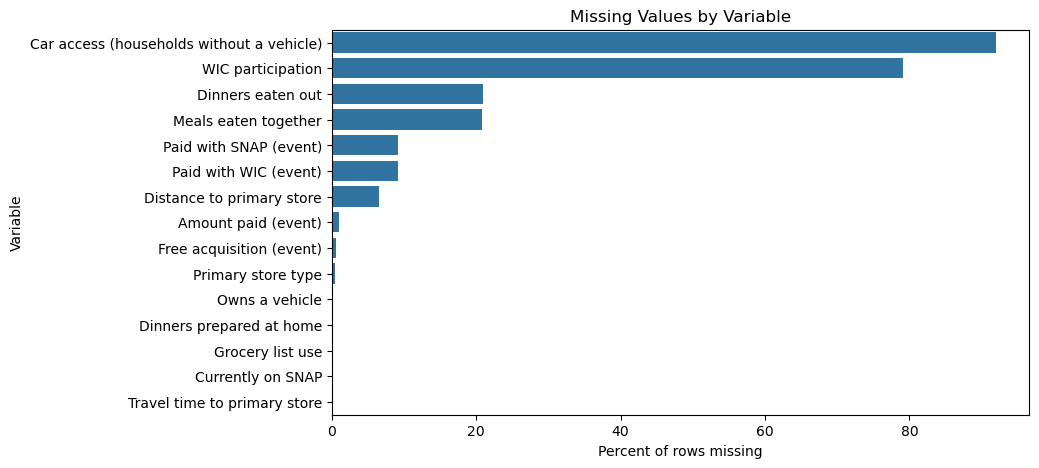

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = missing_before.reset_index().rename(columns={'index': 'variable'})
plot_data['variable'] = readable(plot_data['variable'])
sns.barplot(data=plot_data, y='variable', x='percent missing', dodge=False, ax=ax)
ax.set_title('Missing Values by Variable')
ax.set_xlabel('Percent of rows missing')
ax.set_ylabel('Variable')
plt.show()

### 4.3 Household data imputations

In [10]:
household_imputed = household_clean.copy()

#caraccess to separate those who have a vehicle vs. no vehicle but access to one vs. no vehicle and no access
household_imputed['caraccess_categorical'] = np.select(
    condlist=[household_imputed['anyvehicle'] == 1,
              (household_imputed['anyvehicle'] == 0) & (household_imputed['caraccess'] == 1),
              (household_imputed['anyvehicle'] == 0) & (household_imputed['caraccess'] == 0)],
    choicelist=['has_vehicle', 'no_vehicle_has_access', 'no_vehicle_no_access'], default=None)

#wichh (households without a WIC-eligible member were skipped (-996 "valid skip"), so they do not receive WIC - assign 0)
household_imputed.loc[household['wichh'] == -996, 'wichh'] = 0

#ndinnersouthh & nmealstogether (for a one person household "meals together" is not meaningful, so recode the skip to 0)
mask_dinners = (household['ndinnersouthh'] == -996) & (household_imputed['hhsize'] == 1)
household_imputed.loc[mask_dinners, 'ndinnersouthh'] = 0
mask_together = (household['nmealstogether'] == -996) & (household_imputed['hhsize'] == 1)
household_imputed.loc[mask_together, 'nmealstogether'] = 0

#primstoredist_d: impute the average distance
household_imputed['primstoredist_d'] = household_imputed['primstoredist_d'].fillna(household_imputed['primstoredist_d'].mean())

missing_summary(household_imputed, 'household').sort_values('missing', ascending=False)

,dataset,missing,percent missing
caraccess,household,4440,92.0
caraccess_categorical,household,493,10.2
primstoretype,household,22,0.5
anyvehicle,household,10,0.2
ndinnersouthh,household,6,0.1
nmealshome,household,4,0.1
snapnowhh,household,2,0.0
primstoretraveltime,household,2,0.0
grocerylistfreq,household,1,0.0
nmealstogether,household,1,0.0


We have reduced the number of missing values. The few that remain are handled later inside the modeling pipeline

### 4.4 FAH event data imputations

In [11]:
fahevent_imputed = fahevent_clean.copy()

#totalpaid: flag imputed rows, then fill with the average spending for the same place type
fahevent_imputed['totalpaid_imputed'] = fahevent_imputed['totalpaid'].isna().astype(int)
fahevent_imputed['totalpaid'] = fahevent_imputed.groupby('placetype')['totalpaid'].transform(lambda s: s.fillna(s.mean()))

missing_summary(fahevent_imputed, 'fahevent')

,dataset,missing,percent missing
free,fahevent,91,0.6
ebt_snap,fahevent,1471,9.2
wic,fahevent,1471,9.2


### 4.5 Check for duplicate records

In [12]:
#Fully duplicated rows and duplicated keys in each dataset
duplicate_check = pd.DataFrame({
    'dataset': ['household', 'fahevent', 'access'],
    'duplicate rows': [household_imputed.duplicated().sum(), fahevent_imputed.duplicated().sum(), access_clean.duplicated().sum()],
    'key': ['hhnum', 'hhnum + eventid', 'hhnum'],
    'duplicate keys': [household_imputed['hhnum'].duplicated().sum(),
                       fahevent_imputed.duplicated(subset=['hhnum', 'eventid']).sum(),
                       access_clean['hhnum'].duplicated().sum()]})
duplicate_check

,dataset,duplicate rows,key,duplicate keys
0,household,0,hhnum,0
1,fahevent,0,hhnum + eventid,0
2,access,0,hhnum,0


No duplicates present in the datasets

## 5. Feature Engineering and Merging

### 5.1 Aggregate the FAH events to the household level
The FAH event file is at the single event level (Ex: one shopping trip), so aggregate up to the household level before merging with the household data.

In [13]:
#Create aggregated features
fah_agg = fahevent_imputed.groupby('hhnum').agg(
    #total spending
    fah_total_spending=('totalpaid', 'sum'),  
    #number of events        
    fah_event_count=('eventid', 'count'), 
    #average spending per event            
    fah_avg_spend_event=('totalpaid', 'mean'), 
    #distinct acquisition days       
    fah_acquisition_days=('daynum', 'nunique'), 
    #no cost events      
    fah_free_event_count=('free', 'sum'), 
    #events with free flag reported            
    fah_free_reported_number=('free', 'count'),  
    #SNAP events     
    fah_snap_event_count=('ebt_snap', 'sum'), 
    #events with SNAP flag reported        
    fah_snap_reported_number=('ebt_snap', 'count'), 
    #WIC events  
    fah_wic_event_count=('wic', 'sum'),     
    #events with WIC flag reported          
    fah_wic_reported_number=('wic', 'count'),
    #distinct place types food was acquired from        
    fah_number_placetypes=('placetype', 'nunique')   
).reset_index()

#Percent of free SNAP and WIC acquisition events
fah_agg['fah_pct_free_events'] = fah_agg['fah_free_event_count'] / fah_agg['fah_free_reported_number']
fah_agg['fah_pct_snap_events'] = fah_agg['fah_snap_event_count'] / fah_agg['fah_snap_reported_number']
fah_agg['fah_pct_wic_events']  = fah_agg['fah_wic_event_count'] / fah_agg['fah_wic_reported_number']

#Delete columns used only for the percent calculations
fah_agg = fah_agg.drop(columns=['fah_free_reported_number', 'fah_snap_reported_number', 'fah_wic_reported_number'])


### 5.2 Merge all three datasets
We want the data at the household level with a one to one mapping between the household data, the aggregated FAH data and the access data.

In [ ]:
df = household_imputed.merge(fah_agg, on='hhnum', how='left', validate='one_to_one')
df = df.merge(access_clean, on='hhnum', how='left', validate='one_to_one')

#households that reported no FAH events during the survey week get NaN from the left merge
count_columns = ['fah_total_spending', 'fah_event_count', 'fah_avg_spend_event', 'fah_acquisition_days',
                 'fah_free_event_count', 'fah_snap_event_count', 'fah_wic_event_count', 'fah_number_placetypes']
print('Households with no FAH events', df['fah_event_count'].isna().sum())
df[df['fah_event_count'].isna()][['hhnum', 'hhsize'] + count_columns].head()

Households with no FAH events 414


,hhnum,hhsize,fah_total_spending,fah_event_count,fah_avg_spend_event,fah_acquisition_days,fah_free_event_count,fah_snap_event_count,fah_wic_event_count,fah_number_placetypes
16,100073,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49,100197,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
66,100262,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
74,100284,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75,100286,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


These NaNs are not truly missing. They are households with no events in that category so they are filled with zeros

In [ ]:
#fill NaNs with zeros
df[count_columns] = df[count_columns].fillna(0)

#double check there are no remaining NaNs
df[df['fah_event_count'].isna()][['hhnum', 'hhsize'] + count_columns].head()

,hhnum,hhsize,fah_total_spending,fah_event_count,fah_avg_spend_event,fah_acquisition_days,fah_free_event_count,fah_snap_event_count,fah_wic_event_count,fah_number_placetypes


### 5.3 Create additional features
Rename variables to readable names, normalize acquisition by household size, and build food-insecurity, season, region and car-access features

In [16]:
#Variables to keep
analysis_columns = {
    'hhnum': 'hhnum', 'hhwgt': 'hhwgt', 'tspsu': 'tspsu', 'tsstrata': 'tsstrata',
    'fah_total_spending': 'fah_total_spending', 'fah_event_count': 'fah_event_count',
    'fah_avg_spend_event': 'fah_avg_spend_event', 'fah_acquisition_days': 'fah_acquisition_days',
    'fah_pct_free_events': 'fah_pct_free_events', 'fah_pct_snap_events': 'fah_pct_snap_events',
    'fah_pct_wic_events': 'fah_pct_wic_events', 'fah_number_placetypes': 'fah_number_placetypes',
    'hhsize': 'hhsize',
    'pctpovguidehh_r': 'income_pct_poverty',
    'grocerylistfreq': 'grocery_list_freq',
    'ndinnersouthh': 'n_dinners_out', 'nmealshome': 'n_meals_home', 'nmealstogether': 'n_meals_together',
    'adltfscat': 'food_security_cat', 'foodsufficient': 'food_sufficient_cat',
    'snapnowhh': 'snap_now', 'wichh': 'wic_hh',
    'caraccess_categorical': 'caraccess_categorical',
    'primstoredist_d': 'primstore_dist', 'primstoretraveltime': 'primstore_traveltime', 'primstoretype': 'primstore_type',
    'nearsmss_dist': 'near_supermkt_dist', 'snap3': 'snap_stores_3mi', 'sm3': 'supermkt_3mi',
    'ss3': 'supercenter_3mi', 'cs3': 'convenience_3mi',
    'region': 'region', 'rural': 'rural', 'nonmetro': 'nonmetro', 'startmon': 'start_month'}

analysis_df = df[list(analysis_columns.keys())].rename(columns=analysis_columns)

#acquisition intensity normalized by household size
analysis_df['fah_spending_pc'] = analysis_df['fah_total_spending'] / analysis_df['hhsize']
analysis_df['fah_events_pc']   = analysis_df['fah_event_count'] / analysis_df['hhsize']

#food insecurity and income features
analysis_df['food_insecure'] = analysis_df['food_security_cat'].isin([3, 4]).astype(int)
#create income as a multiple of the poverty line feature
analysis_df['income_x_poverty'] = analysis_df['income_pct_poverty'] / 100.0

#season from the survey start month
seasons = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring', 6: 'summer', 7: 'summer', 8: 'summer', 9: 'fall', 10: 'fall', 11: 'fall'}
analysis_df['season'] = analysis_df['start_month'].map(seasons)

#clean car access variable
analysis_df['caraccess_categorical'] = analysis_df['caraccess_categorical'].fillna('unknown')

#regions variable creation
regions = {1: 'northeast', 2: 'midwest', 3: 'south', 4: 'west'}
analysis_df['region_lbl'] = analysis_df['region'].map(regions)

#labels for EDA plots
grocery_labels = {1: 'Never', 2: 'Seldom', 3: 'Sometimes', 4: 'Most of the time', 5: 'Almost always'}
food_security_labels = {1: 'High', 2: 'Marginal', 3: 'Low', 4: 'Very low'}
analysis_df['grocery_list_lbl'] = pd.Categorical(analysis_df['grocery_list_freq'].map(grocery_labels), categories=list(grocery_labels.values()), ordered=True)
analysis_df['food_security_lbl'] = pd.Categorical(analysis_df['food_security_cat'].map(food_security_labels), categories=list(food_security_labels.values()), ordered=True)

#income groups relative to the federal poverty line
#note: 185% is the WIC and reduced price school meal cutoff
analysis_df['income_group'] = pd.cut(analysis_df['income_pct_poverty'], bins=[-np.inf, 100, 185, 300, np.inf], labels=['<100 percent FPL', '100-185 percent FPL', '185-300 percent FPL', '300+ percent FPL'])

#log transformation of the skewed outcome
#note: using log1p because some households have zero spending
analysis_df['log_fah_spending'] = np.log1p(analysis_df['fah_spending_pc'])

analysis_df.head()

,hhnum,hhwgt,tspsu,tsstrata,fah_total_spending,fah_event_count,fah_avg_spend_event,fah_acquisition_days,fah_pct_free_events,fah_pct_snap_events,...,fah_spending_pc,fah_events_pc,food_insecure,income_x_poverty,season,region_lbl,grocery_list_lbl,food_security_lbl,income_group,log_fah_spending
0,100012,6056.913412,14,15,133.57,6.0,22.261667,5.0,0.000000,0.0,...,26.714000,1.2,0,2.073601,winter,south,Sometimes,Marginal,185-300 percent FPL,3.321938
1,100015,26741.184558,13,17,40.56,6.0,6.760000,4.0,0.000000,0.0,...,40.560000,6.0,0,1.289167,summer,south,Sometimes,Marginal,100-185 percent FPL,3.727138
2,100024,31665.579066,12,7,82.97,3.0,27.656667,2.0,0.000000,0.0,...,41.485000,1.5,0,3.985063,summer,midwest,Seldom,Marginal,300+ percent FPL,3.749151
3,100026,5686.761977,35,14,122.95,9.0,13.661111,5.0,0.333333,0.0,...,61.475000,4.5,1,1.427627,summer,south,Never,Low,100-185 percent FPL,4.134766
4,100028,1067.431417,51,24,88.99,7.0,12.712857,6.0,0.000000,0.0,...,12.712857,1.0,1,1.373490,spring,northeast,Seldom,Very low,100-185 percent FPL,2.618334


## 6. Outlier Analysis
Look for anomalies in the main outcome and in the key continuous predictors using boxplots and the 1.5 × IQR rule.

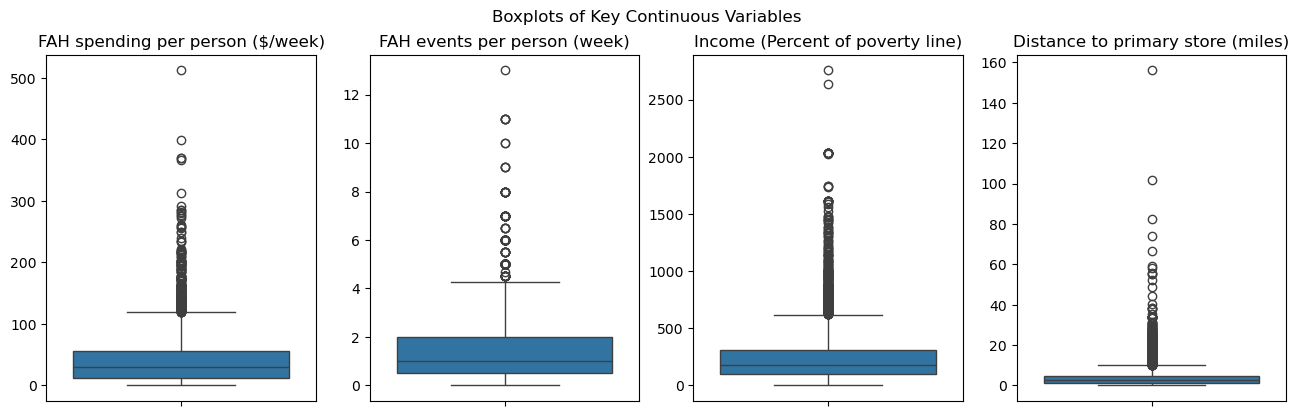

In [17]:
#variables to plot and check for outliers
outlier_vars = {'fah_spending_pc': 'FAH spending per person ($/week)',
                'fah_events_pc': 'FAH events per person (week)',
                'income_pct_poverty': 'Income (Percent of poverty line)',
                'primstore_dist': 'Distance to primary store (miles)'}

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, outlier_vars.items()):
    sns.boxplot(y=analysis_df[col], ax=ax)
    ax.set_title(label)
    ax.set_ylabel('')
fig.suptitle('Boxplots of Key Continuous Variables')
plt.show()

In [ ]:
#IQR outliers for each variable
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (series < lower) | (series > upper)
    return pd.Series({'lower bound': round(lower, 1), 'upper bound': round(upper, 1),'number of outliers': int(is_outlier.sum()), 'percent of outliers': round(100 * is_outlier.mean(), 1), 'median': round(series.median(), 1), 'max': round(series.max(), 1)})

outlier_table = pd.DataFrame({label: iqr_outliers(analysis_df[col].dropna()) for col, label in outlier_vars.items()}).T
outlier_table

,lower bound,upper bound,number of outliers,percent of outliers,median,max
FAH spending per person ($/week),-51.4,119.4,235.0,4.9,30.3,512.4
FAH events per person (week),-1.8,4.2,179.0,3.7,1.0,13.0
Income (Percent of poverty line),-209.9,618.0,330.0,6.8,174.5,2755.6
Distance to primary store (miles),-4.0,10.0,487.0,10.1,2.6,156.1


In [19]:
#share of households with $0 FAH spending during the survey week
zero_spending_share = (analysis_df['fah_total_spending'] == 0).mean()
print(f'Households with $0 FAH spending: {zero_spending_share:.1%}')

Households with $0 FAH spending: 9.7%


We keep outliers because they represent households that spent nothing or spent a lot in a given week, all of which are of interest

## 7. Exploratory Data Analysis

### 7.1 Distribution of the outcome variables

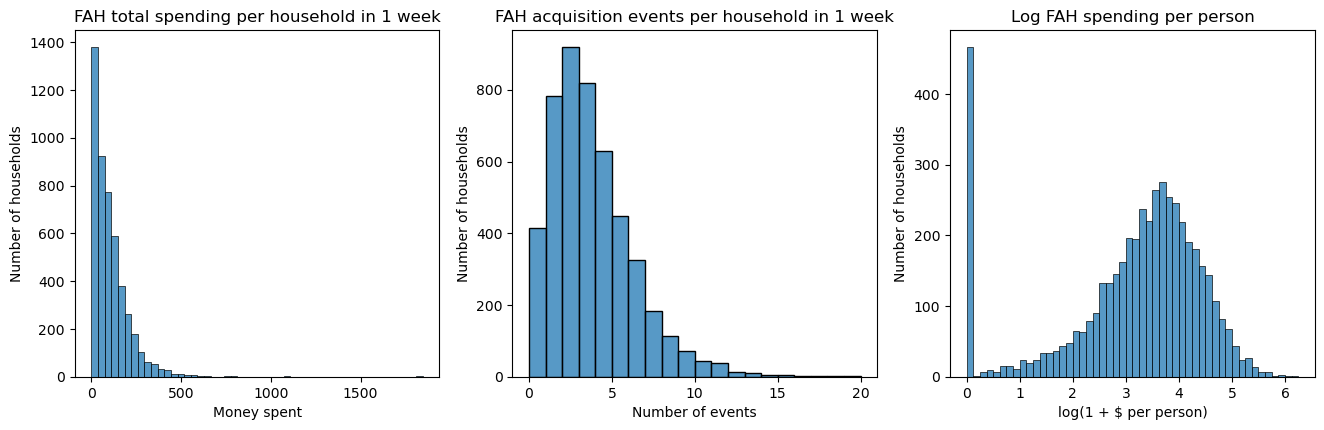

In [20]:
#Create plots of the outcome variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(analysis_df['fah_total_spending'], bins=50, ax=axes[0])
axes[0].set_title('FAH total spending per household in 1 week')
axes[0].set_xlabel('Money spent')
axes[0].set_ylabel('Number of households')

sns.histplot(analysis_df['fah_event_count'], bins=20, ax=axes[1])
axes[1].set_title('FAH acquisition events per household in 1 week')
axes[1].set_xlabel('Number of events')
axes[1].set_ylabel('Number of households')

sns.histplot(analysis_df['log_fah_spending'], bins=50, ax=axes[2])
axes[2].set_title('Log FAH spending per person')
axes[2].set_xlabel('log(1 + $ per person)')
axes[2].set_ylabel('Number of households')

plt.show()

Both raw outcomes are right-skewed. Using log1p (log of 1 + x), since many households have 0 spending.

### 7.2 Categorical variables

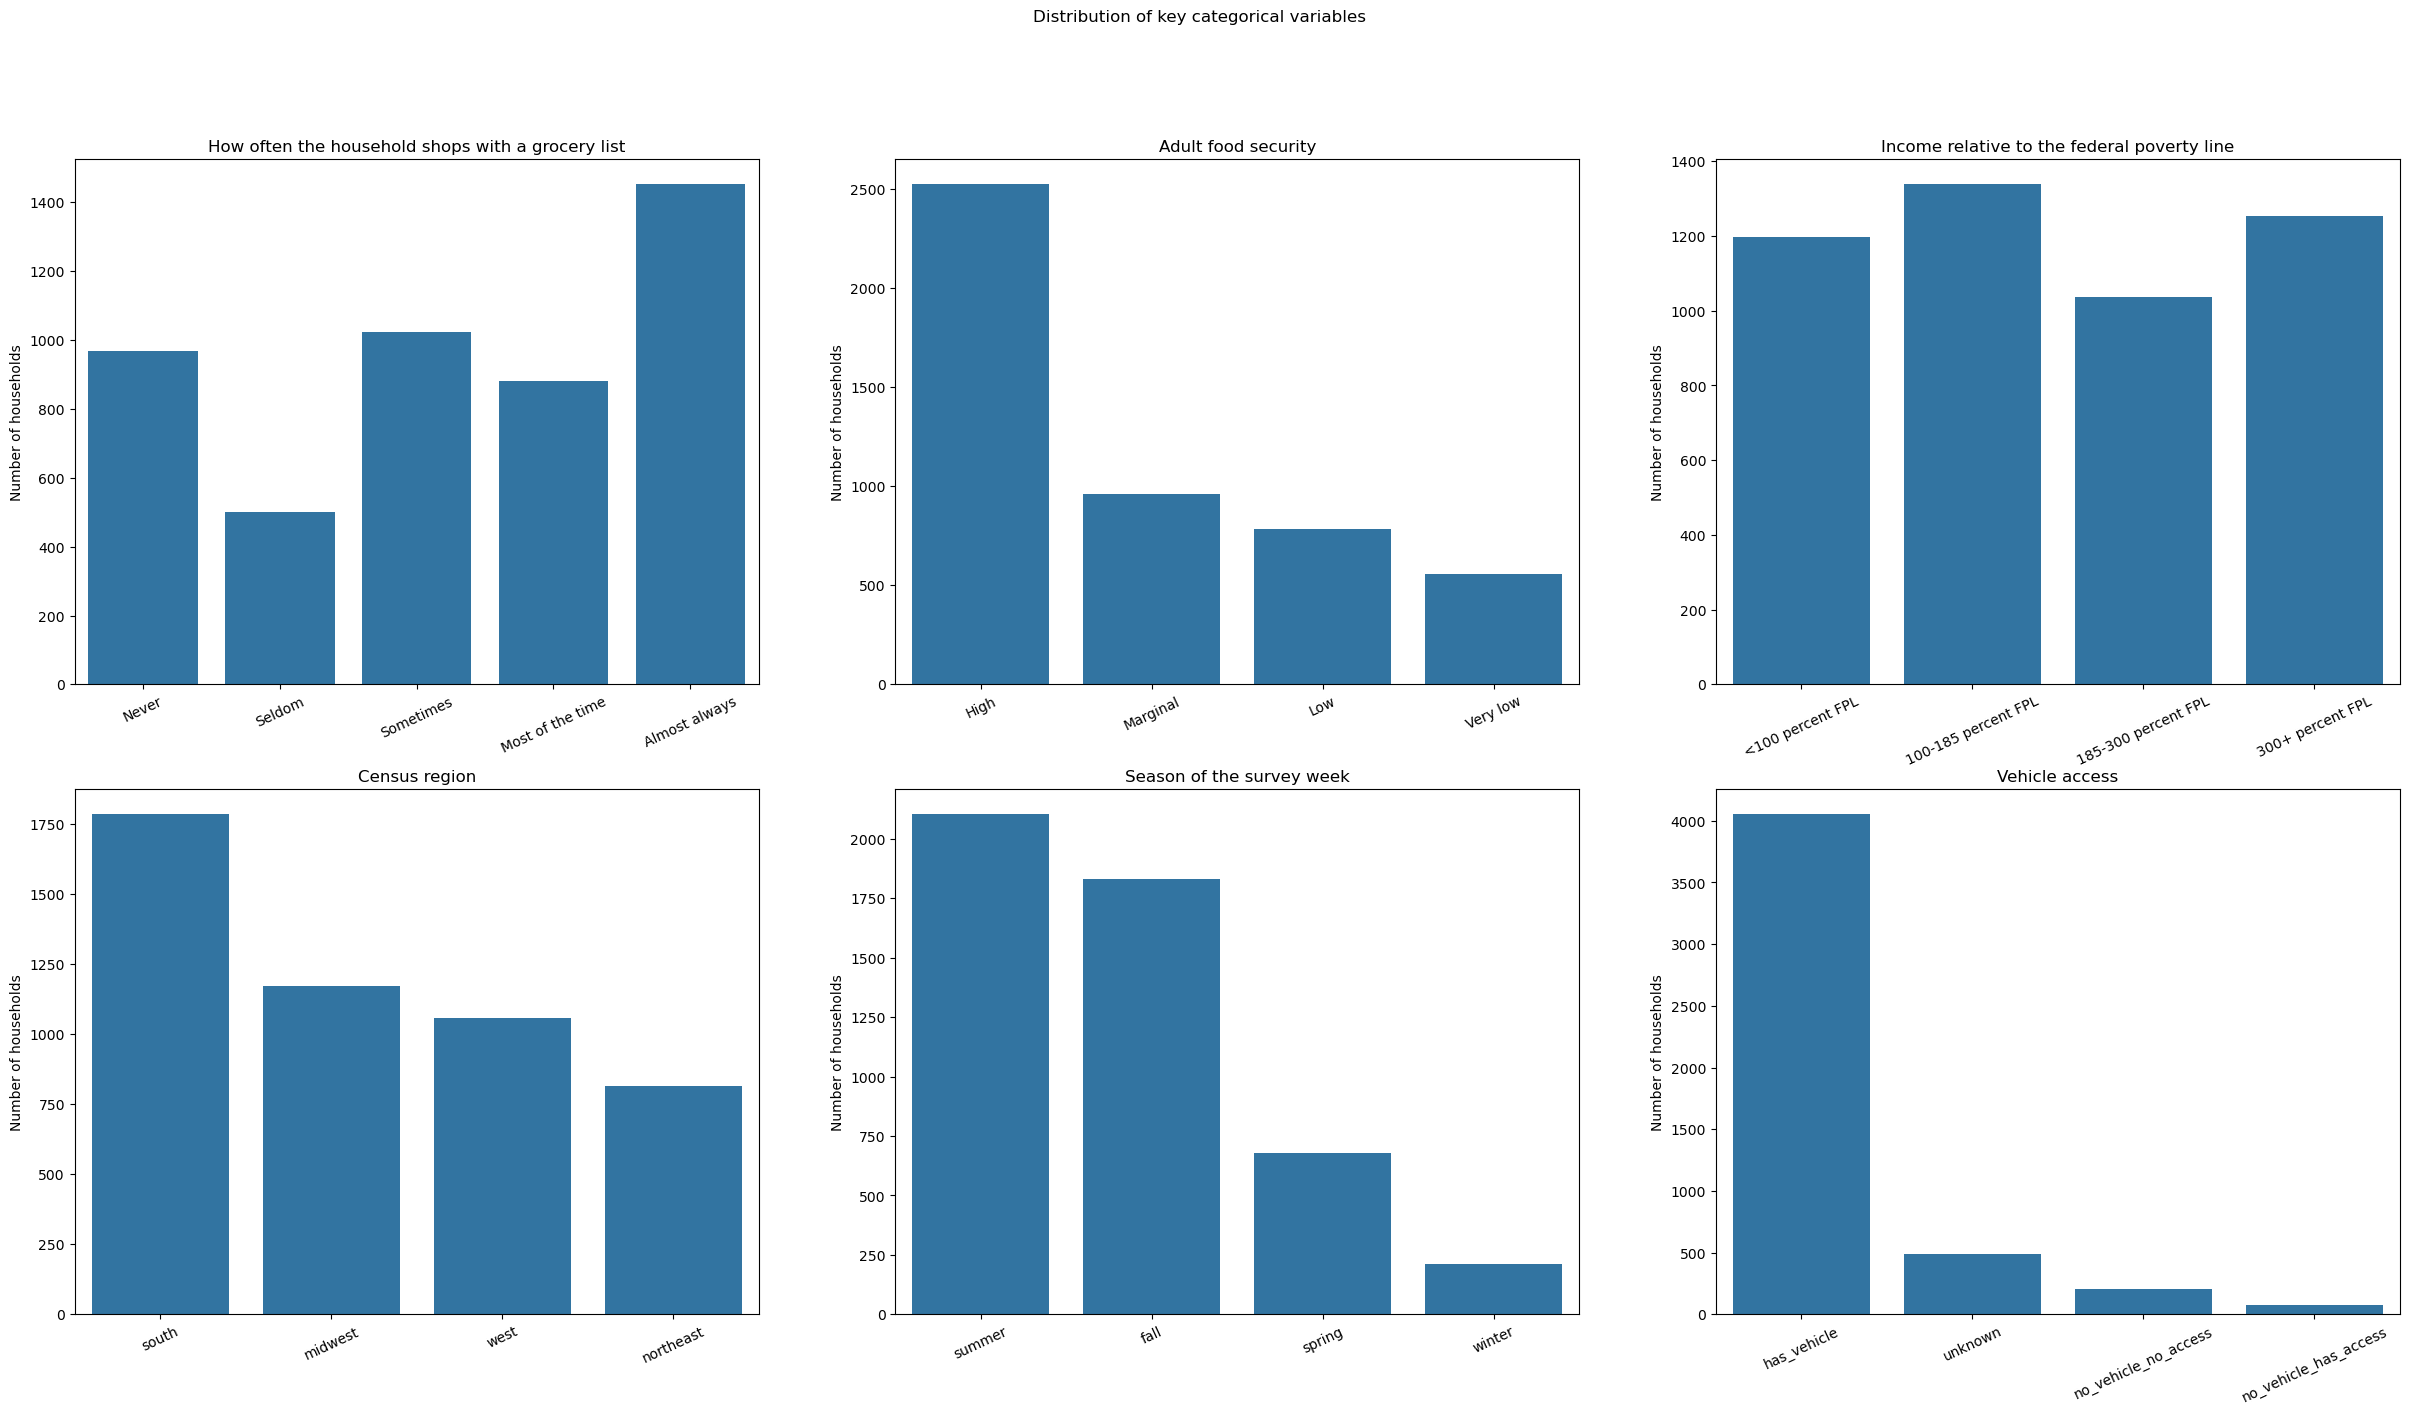

In [21]:
#create plots of the categorical variables of interest
categorical_plots = [('grocery_list_lbl', 'How often the household shops with a grocery list'),
                     ('food_security_lbl', 'Adult food security'),
                     ('income_group', 'Income relative to the federal poverty line'),
                     ('region_lbl', 'Census region'),
                     ('season', 'Season of the survey week'),
                     ('caraccess_categorical', 'Vehicle access')]

fig, axes = plt.subplots(2, 3, figsize=(30,15))
for ax, (col, title) in zip(axes.flat, categorical_plots):
    order = analysis_df[col].cat.categories if hasattr(analysis_df[col], 'cat') else analysis_df[col].value_counts().index
    sns.countplot(data=analysis_df, x=col, order=order, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Number of households')
    ax.tick_params(axis='x', rotation=25)
fig.suptitle('Distribution of key categorical variables')

plt.show()

### 7.3 FAH spending across income and food-planning groups

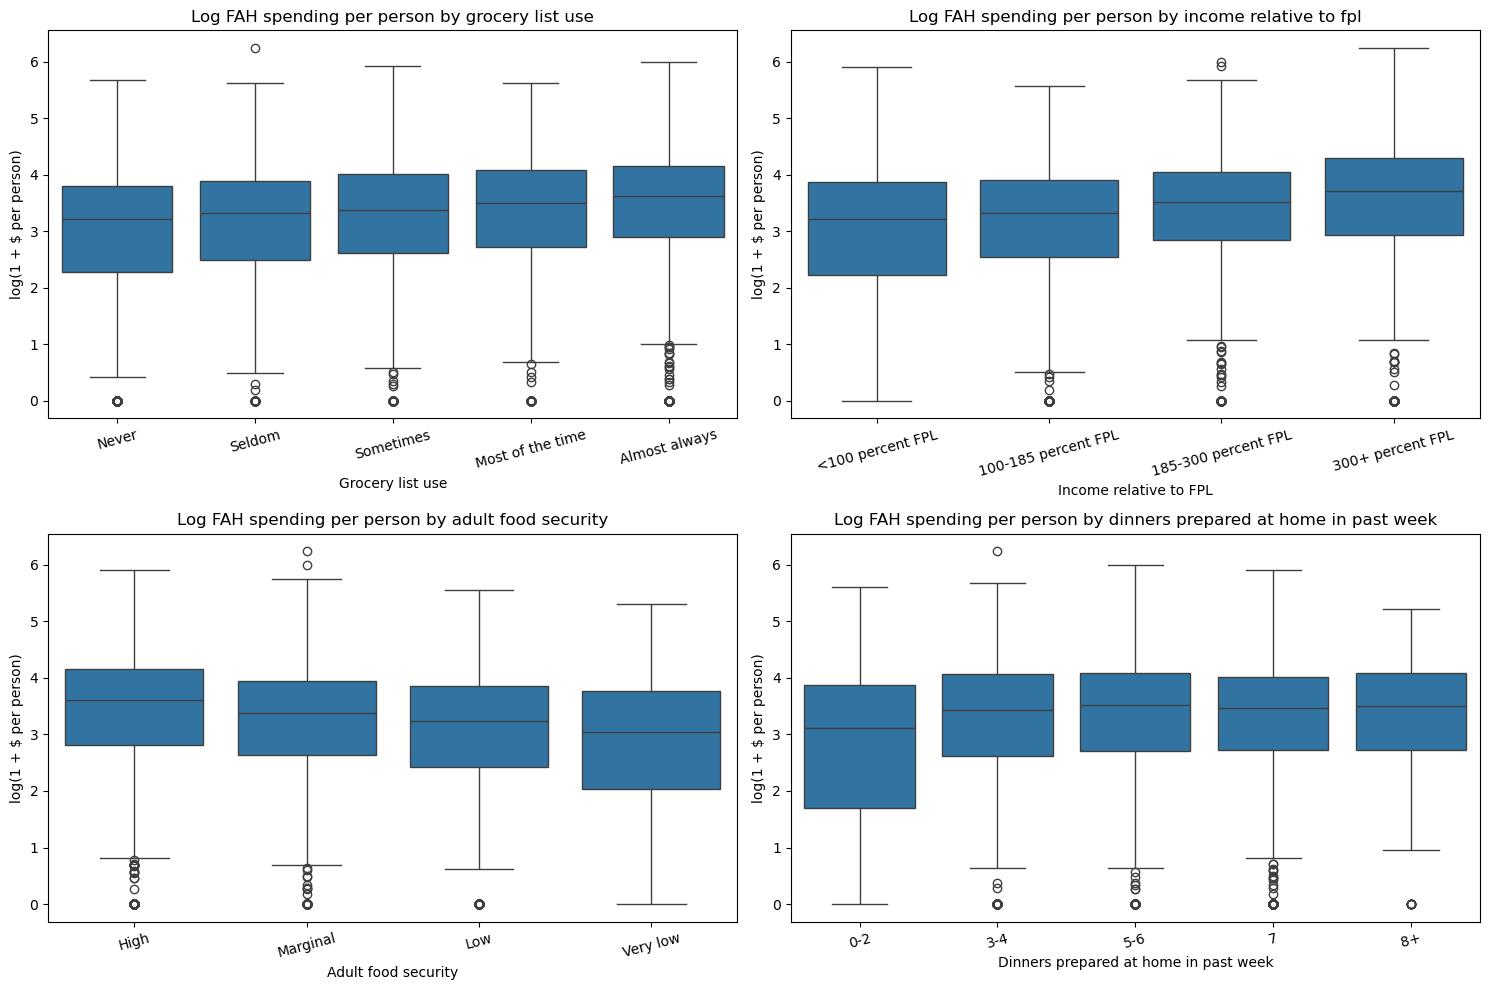

In [22]:
#bin meals prepared at home into groups for plotting
analysis_df['meals_home_group'] = pd.cut(analysis_df['n_meals_home'], bins=[-1, 2, 4, 6, 7, np.inf], labels=['0-2', '3-4', '5-6', '7', '8+'])

group_plots = [('grocery_list_lbl', 'Grocery list use'),
               ('income_group', 'Income relative to FPL'),
               ('food_security_lbl', 'Adult food security'),
               ('meals_home_group', 'Dinners prepared at home in past week')]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, title) in zip(axes.flat, group_plots):
    sns.boxplot(data=analysis_df, x=col, y='log_fah_spending', ax=ax)
    ax.set_title(f'Log FAH spending per person by {title.lower()}')
    ax.set_xlabel(title)
    ax.set_ylabel('log(1 + $ per person)')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

These relationships run opposite to the hypothesis that planning behaviors go with lower acquisition. Households that plan with lists, cook at home more, and have higher incomes acquire more food at home. Part of this is likely confounding (list use and cooking at home both rise with income), so the models will estimate each variable while holding the others constant.

### 7.4 Continuous relationships

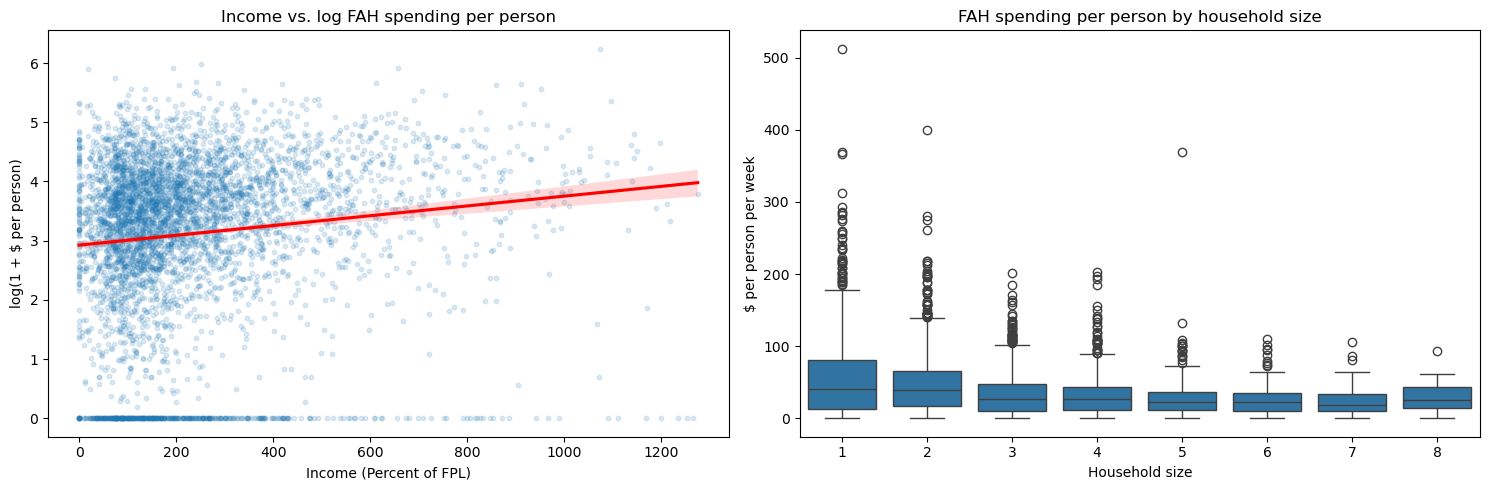

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

#Income vs spending plot
#limit x axis to 99th percentile
income_cap = analysis_df['income_pct_poverty'].quantile(0.99)
plot_df = analysis_df[analysis_df['income_pct_poverty'] <= income_cap]
sns.regplot(data=plot_df, x='income_pct_poverty', y='log_fah_spending', ax=axes[0],
            scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'})
axes[0].set_title('Income vs. log FAH spending per person')
axes[0].set_xlabel('Income (Percent of FPL)')
axes[0].set_ylabel('log(1 + $ per person)')

#Household size vs spending per person plot
sns.boxplot(data=analysis_df[analysis_df['hhsize'] <= 8], x='hhsize', y='fah_spending_pc', ax=axes[1])
axes[1].set_title('FAH spending per person by household size')
axes[1].set_xlabel('Household size')
axes[1].set_ylabel('$ per person per week')

plt.tight_layout()
plt.show()

Income has a positive but weak relationship with log spending per person

### 7.5 Correlation matrix

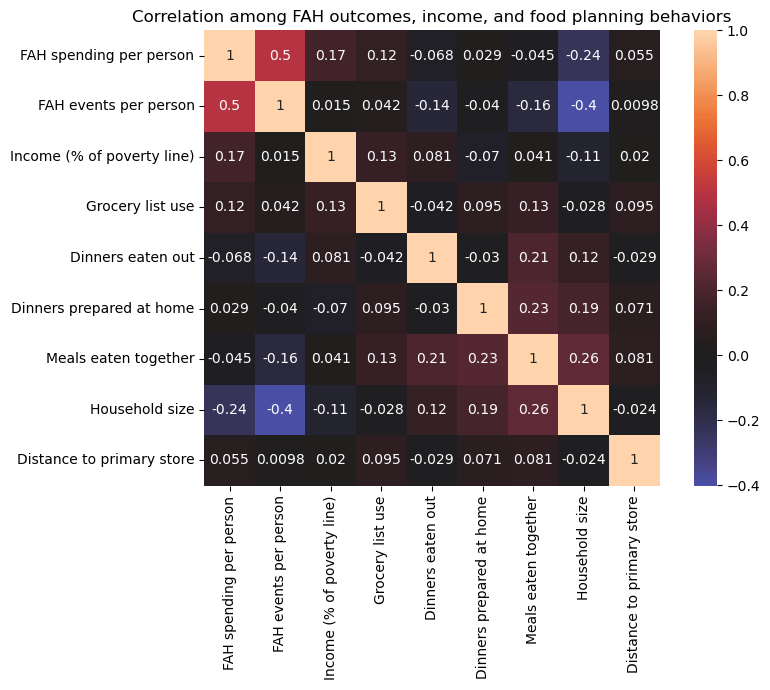

In [24]:
corr_columns = ['fah_spending_pc', 'fah_events_pc', 'income_pct_poverty', 'grocery_list_freq', 'n_dinners_out', 'n_meals_home', 'n_meals_together', 'hhsize', 'primstore_dist']
corr = analysis_df[corr_columns].corr()
corr.index, corr.columns = readable(corr.index), readable(corr.columns)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, center=0, ax=ax, square=True)
ax.set_title('Correlation among FAH outcomes, income, and food planning behaviors')
plt.tight_layout()
plt.show()

The FAH events and FAH spending variables are moderately correlated but not redundant, since people can acquire the same amount of food in many trips or few. Household size has the strongest correlation with spending per person. Income and grocery list use are weakly positively correlated with spending. Eating out is slightly negatively correlated with acquisition, which is intuitive. No pair of predictors is highly correlated, so multicollinearity is not a concern for the linear model.

## 8. Baseline Modeling

### 8.1 Approach and evaluation metric
The baseline is a multiple linear regression predicting log_fah_spending (log of 1 + weekly FAH spending per person) from income, food-planning behaviors and controls:
- Income: income_x_poverty
- Food planning / meal routines: grocery_list_freq, n_dinners_out, n_meals_home, n_meals_together
- Controls: hhsize, food_insecure, snap_now, wic_hh, primstore_dist, rural, caraccess_categorical, region_lbl, season

**Evaluation metric:** The primary metric is MSE on the test set, as well as RMSE and R².
- MSE is the loss linear regression minimizes and penalizes large errors heavily, so it is the natural metric for comparing regression models on the same outcome. Because the outcome is on a log scale, RMSE can be converted to a typical multiplicative error in per-person spending where a prediction is typically off by a factor of e^RMSE.
- R² is reported as the secondary metric because it is unit free and directly answers "how much of the household-to-household variation in spending do these characteristics explain?"

In [25]:
#Select the modeling variables (income, food planning behaviors, and controls) and the outcome
model_columns = ['hhsize', 'food_insecure', 'snap_now', 'wic_hh', 'primstore_dist', 'rural', 'caraccess_categorical', 'region_lbl', 'season', 'income_x_poverty', 'grocery_list_freq', 'n_dinners_out', 'n_meals_home', 'n_meals_together', 'log_fah_spending']
model_data = analysis_df[model_columns].copy()

#define X and y and split into training and test data
#missing predictor values are handled by the pipeline imputation steps, fit on training data only
X = model_data.drop(columns=['log_fah_spending'])
y = model_data['log_fah_spending']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=42)

print('Training set shape:', X_train.shape)
print('Test set shape:', X_test.shape)

Training set shape: (3378, 14)
Test set shape: (1448, 14)


In [26]:
numerical_features = ['hhsize', 'food_insecure', 'snap_now', 'wic_hh', 'primstore_dist', 'rural', 'income_x_poverty', 'grocery_list_freq', 'n_dinners_out', 'n_meals_home', 'n_meals_together']
categorical_features = ['caraccess_categorical', 'region_lbl', 'season']

#numeric: replace missing values with the median, then standardize
numeric_pipeline = Pipeline([
                    ('impute', SimpleImputer(strategy='median')),
                    ('scale', StandardScaler())])

#categorical: replace missing values with the mode, then one hot encode
categorical_pipeline = Pipeline([
                    ('impute', SimpleImputer(strategy='most_frequent')),
                    ('encode', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))])

preprocessor = ColumnTransformer([
                    ('num', numeric_pipeline, numerical_features),
                    ('cat', categorical_pipeline, categorical_features)])

#function to get clean feature names
def get_feature_names(fitted_processor):
    return [name.split('__', 1)[1] for name in fitted_processor.get_feature_names_out()]

#function to compute the evaluation metrics
def evaluate(model, name):
    train_pred, test_pred = model.predict(X_train), model.predict(X_test)
    return {'Model': name, 'Train MSE': mean_squared_error(y_train, train_pred), 'Test MSE': mean_squared_error(y_test, test_pred), 'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)), 'Train R2': r2_score(y_train, train_pred), 'Test R2': r2_score(y_test, test_pred)}



### 8.2 Naive reference model - always predicts the training mean

In [27]:
naive_model = DummyRegressor(strategy='mean').fit(X_train, y_train)
naive_results = evaluate(naive_model, 'Naive mean (reference)')

#Drop the text 'Model' entry and convert the remaining metrics to float so they can be rounded
pd.Series(naive_results).drop('Model').astype(float).round(4)

Train MSE    1.7829
Test MSE     1.9694
Test RMSE    1.4033
Train R2     0.0000
Test R2     -0.0005
dtype: float64

### 8.3 Baseline model - multiple linear regression

In [28]:
linear_pipeline = Pipeline([('preprocessor', preprocessor),
                            ('linear', LinearRegression())])
linear_pipeline.fit(X_train, y_train)

linear_results = evaluate(linear_pipeline, 'Linear Regression (baseline)')
pd.DataFrame([naive_results, linear_results]).set_index('Model').round(4)

,Train MSE,Test MSE,Test RMSE,Train R2,Test R2
Model,,,,,
Naive mean (reference),1.7829,1.9694,1.4033,0.0000,-0.0005
Linear Regression (baseline),1.6773,1.8593,1.3636,0.0593,0.0554


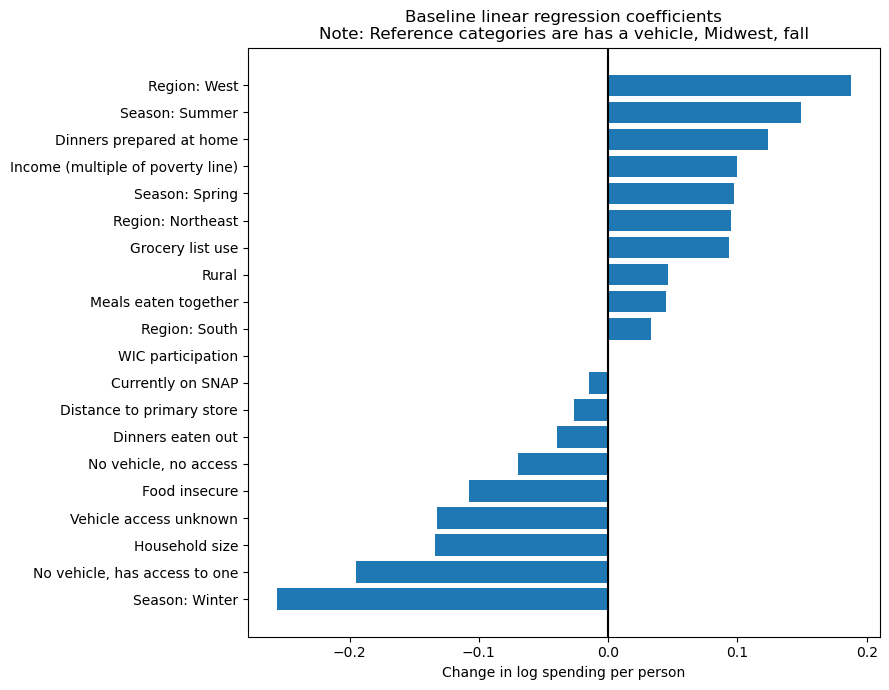

In [ ]:
#Coefficients
#Note: features are standardized so magnitudes are comparable. A change in log spending per 1 SD
linear_feature_names = get_feature_names(linear_pipeline.named_steps['preprocessor'])
linear_coefficients = pd.Series(linear_pipeline.named_steps['linear'].coef_, index=linear_feature_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(readable(linear_coefficients.index), linear_coefficients.values)
ax.axvline(0, color='black')
ax.set_title('Baseline linear regression coefficients\nNote: Reference categories are has a vehicle, Midwest, fall')
ax.set_xlabel('Change in log spending per person')
plt.tight_layout()
plt.show()

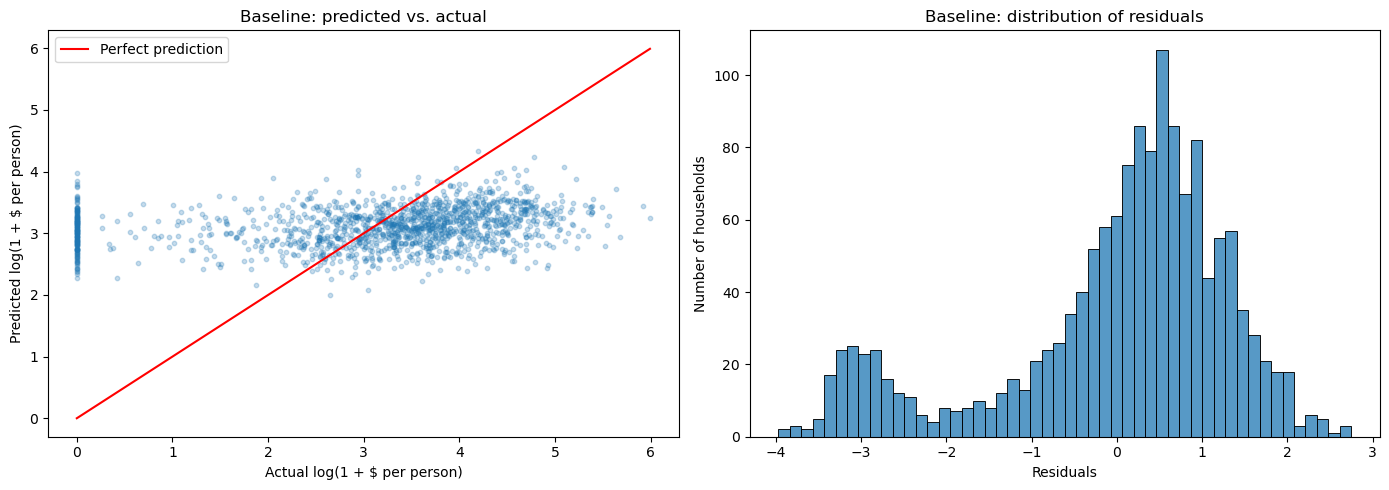

In [30]:
#diagnostic plots -  predicted vs. actual and residual distribution on the test set
linear_test_predictions = linear_pipeline.predict(X_test)
residuals = y_test - linear_test_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, linear_test_predictions, alpha=0.25, s=10)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color='red',label='Perfect prediction')
axes[0].set_title('Baseline: predicted vs. actual')
axes[0].set_xlabel('Actual log(1 + $ per person)')
axes[0].set_ylabel('Predicted log(1 + $ per person)')
axes[0].legend()

sns.histplot(residuals, bins=50, ax=axes[1])
axes[1].set_title('Baseline: distribution of residuals')
axes[1].set_xlabel('Residuals')
axes[1].set_ylabel('Number of households')
plt.tight_layout()
plt.show()

**Interpreting the baseline**
- Evaluation metrics: the baseline linear regression has a test MSE of 1.9 versus 2.0 for the naive mean model. It is about a 6% reduction in error. Its test R² is 0.055, meaning income, food-planning behaviors and the controls together explain about 6% of the household-to-household variation in weekly FAH spending per person. Train and test R² are close, so the model is not overfitting

- An RMSE of 1.4 on the log scale is large: e^1.36 ≈ 3.9, so a typical prediction of weekly spending per person is off by a factor of about 4. The predicted vs actual plot shows that the model predicts a narrow band and cannot reach the households with zero spending which produce the separate cluster of residuals

- More dinners prepared at home, higher income and more frequent grocery list use are each associated with higher FAH spending per person. Larger household size, food insecurity and eating out more are associated with lower spending. Households surveyed in winter spent less than those surveyed in fall (note: only about 200 households were surveyed in winter, all in December or January, so this estimate rests on a small group), and households in the West spent more than those in the midwest

## 9. Modeling with Grid Search

Every model below follows the same steps:
1. Build a pipeline with the preprocessor from section 8 (median / mode imputation, standardizing, one hot encoding) and the model
2. Define a grid of hyperparameters and search it with gridsearchCV
3. Take the best estimator, predict on the training and test data, and compute metrics

### 9.1 Linear Regression

In [31]:
#build a pipeline
linear_pipeline = Pipeline([('preprocessor', preprocessor),
                            ('linear', LinearRegression())])

#grid search over whether to fit an intercept
linear_params = {'linear__fit_intercept': [True, False]}
linear_grid = GridSearchCV(linear_pipeline, linear_params, scoring='neg_mean_squared_error', cv=4)

#linear regression modeling
linear_grid.fit(X_train, y_train)
linear_best = linear_grid.best_estimator_
linear_training_predictions = linear_best.predict(X_train)
linear_test_predictions = linear_best.predict(X_test)

#compute the errors
linear_training_mse = mean_squared_error(y_train, linear_training_predictions)
linear_test_mse = mean_squared_error(y_test, linear_test_predictions)
linear_trainingr2 = r2_score(y_train, linear_training_predictions)
linear_testr2 = r2_score(y_test, linear_test_predictions)

#get the coefficients
linear_feature_names = get_feature_names(linear_best.named_steps['preprocessor'])
linear_coefficients = pd.Series(linear_best.named_steps['linear'].coef_, index=linear_feature_names).sort_values()
print('\nStrongest coefficients associated with lower spending:')
print(linear_coefficients.head(5))
print('\nStrongest coefficients associated with higher spending:')
print(linear_coefficients.tail(5))

print('\nBest parameters:', linear_grid.best_params_)
print(f'Training MSE:', linear_training_mse)
print(f'Test MSE:', linear_test_mse)
print(f'Training R2:', linear_trainingr2)
print(f'Test R2:', linear_testr2)


Strongest coefficients associated with lower spending:
season_winter                                 -0.256425
caraccess_categorical_no_vehicle_has_access   -0.194799
hhsize                                        -0.133987
caraccess_categorical_unknown                 -0.132242
food_insecure                                 -0.107615
dtype: float64

Strongest coefficients associated with higher spending:
season_spring       0.096984
income_x_poverty    0.099476
n_meals_home        0.123568
season_summer       0.148949
region_lbl_west     0.188024
dtype: float64

Best parameters: {'linear__fit_intercept': True}
Training MSE: 1.6772909659373907
Test MSE: 1.859296423064212
Training R2: 0.05925350141879382
Test R2: 0.055411151456611685


### 9.2 Polynomial Regression on Continuous Variables

Adds squared terms and pairwise interactions of the numeric features (ex: income × grocery list use)

In [32]:
#pipeline to process features with polynomial terms on the numeric variables
numeric_poly_pipeline = Pipeline([
                    ('impute', SimpleImputer(strategy='median')),
                    ('poly', PolynomialFeatures(include_bias=False)),
                    ('scale', StandardScaler())])

polynomial_preprocessor = ColumnTransformer([
                    ('num', numeric_poly_pipeline, numerical_features),
                    ('cat', categorical_pipeline, categorical_features)])

polynomial_pipeline = Pipeline([
                    ('preprocessor', polynomial_preprocessor),
                    ('linear', LinearRegression())])

#grid search over the polynomial degree
degrees = {'preprocessor__num__poly__degree': [1, 2, 3]}
polynomial_grid = GridSearchCV(polynomial_pipeline, degrees, scoring='neg_mean_squared_error', cv=4, return_train_score=True)

#fit model and make predictions
polynomial_grid.fit(X_train, y_train)
polynomial_best = polynomial_grid.best_estimator_
polynomial_training_predictions = polynomial_best.predict(X_train)
polynomial_test_predictions = polynomial_best.predict(X_test)

#get error metrics
polynomial_trainingr2 = r2_score(y_train, polynomial_training_predictions)
polynomial_testr2 = r2_score(y_test, polynomial_test_predictions)
polynomial_training_mse = mean_squared_error(y_train, polynomial_training_predictions)
polynomial_test_mse = mean_squared_error(y_test, polynomial_test_predictions)

best_polynomial_degree = polynomial_grid.best_params_['preprocessor__num__poly__degree']
print(f'Best polynomial degree: {best_polynomial_degree}')
print(f'Training R2:', polynomial_trainingr2)
print(f'Test R2:', polynomial_testr2)
print(f'Training MSE:', polynomial_training_mse)
print(f'Test MSE:', polynomial_test_mse)

Best polynomial degree: 1
Training R2: 0.05925350141879382
Test R2: 0.055411151456611685
Training MSE: 1.6772909659373907
Test MSE: 1.859296423064212


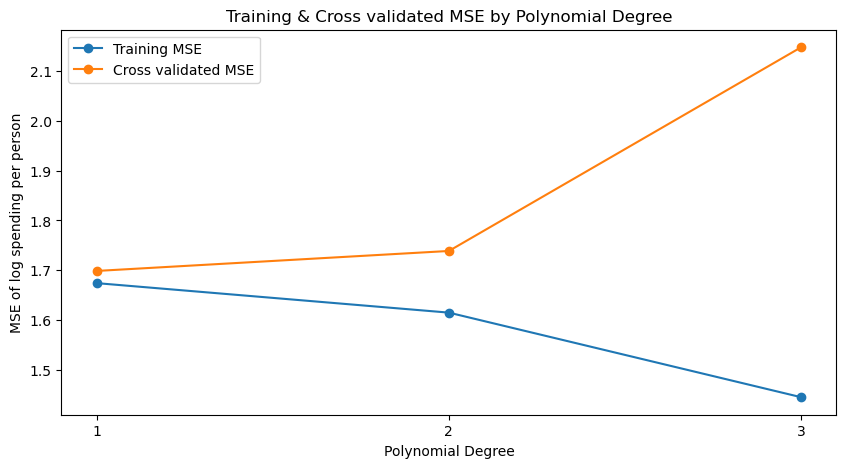

In [33]:
polynomial_cv_results = pd.DataFrame(polynomial_grid.cv_results_)

plt.figure(figsize=(10, 5))
plt.plot(polynomial_cv_results['param_preprocessor__num__poly__degree'], -polynomial_cv_results['mean_train_score'], marker='o', label='Training MSE')
plt.plot(polynomial_cv_results['param_preprocessor__num__poly__degree'], -polynomial_cv_results['mean_test_score'], marker='o', label='Cross validated MSE')
plt.xticks([1, 2, 3])
plt.xlabel('Polynomial Degree')
plt.ylabel('MSE of log spending per person')
plt.title('Training & Cross validated MSE by Polynomial Degree')
plt.legend()
plt.show()

### 9.3 Ridge Regression

In [34]:
#ridge pipeline
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('ridge', Ridge())])

alphas = {'ridge__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]}
ridge_grid = GridSearchCV(ridge_pipeline, alphas, scoring='neg_mean_squared_error', cv=4)

#fit model and make predictions
ridge_grid.fit(X_train, y_train)
ridge_best = ridge_grid.best_estimator_
ridge_training_predictions = ridge_best.predict(X_train)
ridge_test_predictions = ridge_best.predict(X_test)

#get error metrics
ridge_trainingr2 = r2_score(y_train, ridge_training_predictions)
ridge_testr2 = r2_score(y_test, ridge_test_predictions)
ridge_training_mse = mean_squared_error(y_train, ridge_training_predictions)
ridge_test_mse = mean_squared_error(y_test, ridge_test_predictions)

print('Best alpha:', ridge_grid.best_params_['ridge__alpha'])
print(f'Training R2:', ridge_trainingr2)
print(f'Test R2:', ridge_testr2)
print(f'Training MSE:', ridge_training_mse)
print(f'Test MSE:', ridge_test_mse)

Best alpha: 100.0
Training R2: 0.05853539453970347
Test R2: 0.05906301420749094
Training MSE: 1.6785713046712498
Test MSE: 1.852108221170127


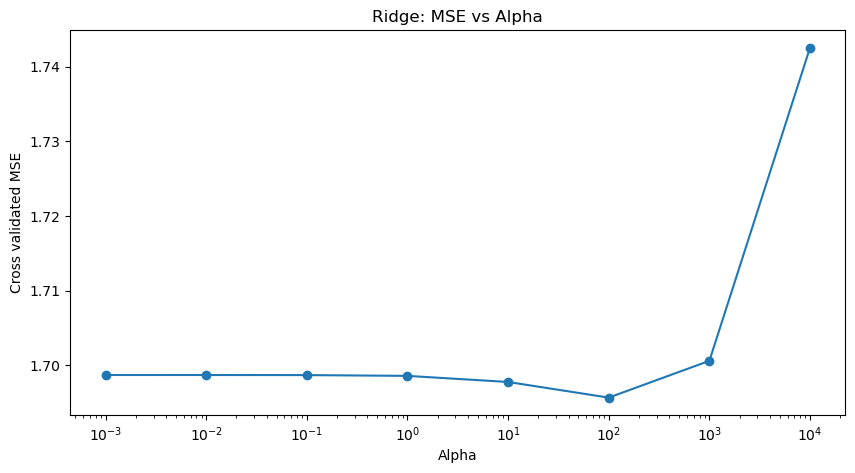

In [35]:
ridge_cv_results = pd.DataFrame(ridge_grid.cv_results_)

plt.figure(figsize=(10, 5))
plt.plot(ridge_cv_results['param_ridge__alpha'].astype(float), -ridge_cv_results['mean_test_score'], marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Cross validated MSE')
plt.title('Ridge: MSE vs Alpha')
plt.show()

### 9.4 Lasso Regression

In [36]:
#build a pipeline
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('lasso', Lasso(max_iter=10000))])

alphas = {'lasso__alpha': [0.00001, 0.0001, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1]}
lasso_grid = GridSearchCV(lasso_pipeline, alphas, scoring='neg_mean_squared_error', cv=4)

#fit the model & get predictions
lasso_grid.fit(X_train, y_train)
lasso_best = lasso_grid.best_estimator_
lasso_training_predictions = lasso_best.predict(X_train)
lasso_test_predictions = lasso_best.predict(X_test)

#get error metrics
lasso_training_mse = mean_squared_error(y_train, lasso_training_predictions)
lasso_test_mse = mean_squared_error(y_test, lasso_test_predictions)
lasso_trainingr2 = r2_score(y_train, lasso_training_predictions)
lasso_testr2 = r2_score(y_test, lasso_test_predictions)

print('Best alpha:', lasso_grid.best_params_['lasso__alpha'])
print(f'Training MSE:', lasso_training_mse)
print(f'Test MSE:', lasso_test_mse)
print(f'Training R2:', lasso_trainingr2)
print(f'Test R2:', lasso_testr2)

Best alpha: 0.005
Training MSE: 1.6799381568303222
Test MSE: 1.8503337010734056
Training R2: 0.057768764653274074
Test R2: 0.059964533660810115


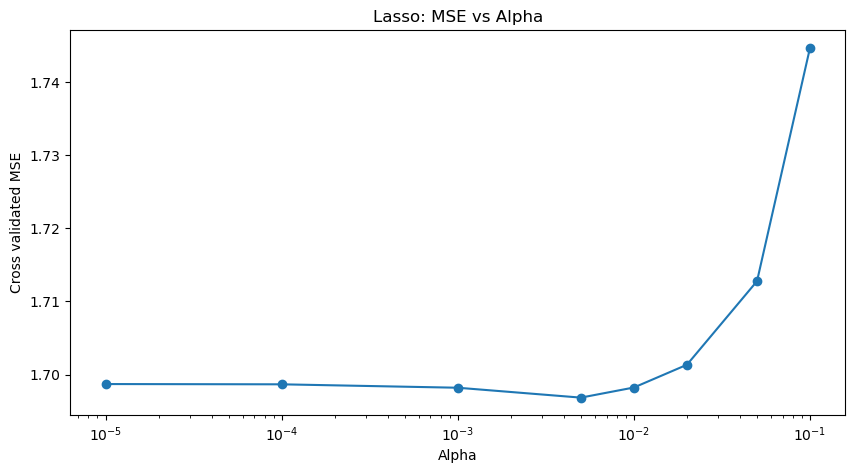

In [37]:
lasso_cv_results = pd.DataFrame(lasso_grid.cv_results_)

plt.figure(figsize=(10, 5))
plt.plot(lasso_cv_results['param_lasso__alpha'].astype(float), -lasso_cv_results['mean_test_score'], marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Cross validated MSE')
plt.title('Lasso: MSE vs Alpha')
plt.show()

Features dropped by Lasso: ['wic_hh', 'region_lbl_south', 'caraccess_categorical_no_vehicle_has_access', 'caraccess_categorical_no_vehicle_no_access']


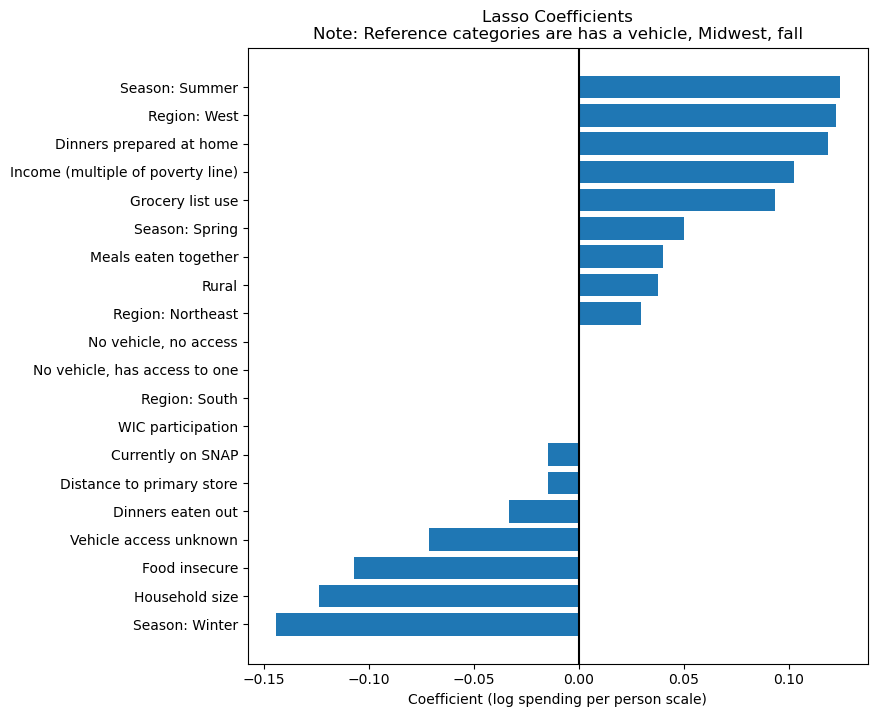

In [38]:
#Coefficients graph
#get the feature names and coefficients
lasso_feature_names = get_feature_names(lasso_best.named_steps['preprocessor'])
lasso_coefficients = pd.Series(lasso_best.named_steps['lasso'].coef_, index=lasso_feature_names).sort_values()

#get features Lasso shrank to exactly zero
print('Features dropped by Lasso:', list(lasso_coefficients[lasso_coefficients == 0].index))

plt.figure(figsize=(8, 8))
plt.barh(readable(lasso_coefficients.index), lasso_coefficients.values)
plt.axvline(0, color='black')
plt.title('Lasso Coefficients\nNote: Reference categories are has a vehicle, Midwest, fall')
plt.xlabel('Coefficient (log spending per person scale)')
plt.show()

### 9.5 Decision Tree

Tree models split households into groups using thresholds (ex: income above or below a cutoff), so they capture nonlinear effects and interactions without having to specify them

In [39]:
#build a pipeline
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('tree', DecisionTreeRegressor(random_state=42))])

tree_params = {'tree__max_depth': [2, 3, 4, 5, 6, 8, 10],
               'tree__min_samples_leaf': [1, 10, 25, 50, 100]}
tree_grid = GridSearchCV(tree_pipeline, tree_params, scoring='neg_mean_squared_error', cv=4)

#fit model and make predictions
tree_grid.fit(X_train, y_train)
tree_best = tree_grid.best_estimator_
tree_training_predictions = tree_best.predict(X_train)
tree_test_predictions = tree_best.predict(X_test)

#get error metrics
tree_training_mse = mean_squared_error(y_train, tree_training_predictions)
tree_test_mse = mean_squared_error(y_test, tree_test_predictions)
tree_trainingr2 = r2_score(y_train, tree_training_predictions)
tree_testr2 = r2_score(y_test, tree_test_predictions)

print('Best parameters:', tree_grid.best_params_)
print(f'Training MSE:', tree_training_mse)
print(f'Test MSE:', tree_test_mse)
print(f'Training R2:', tree_trainingr2)
print(f'Test R2:', tree_testr2)

Best parameters: {'tree__max_depth': 4, 'tree__min_samples_leaf': 25}
Training MSE: 1.6435411372761861
Test MSE: 1.87171804341162
Training R2: 0.07818285463509744
Test R2: 0.049100525611559864


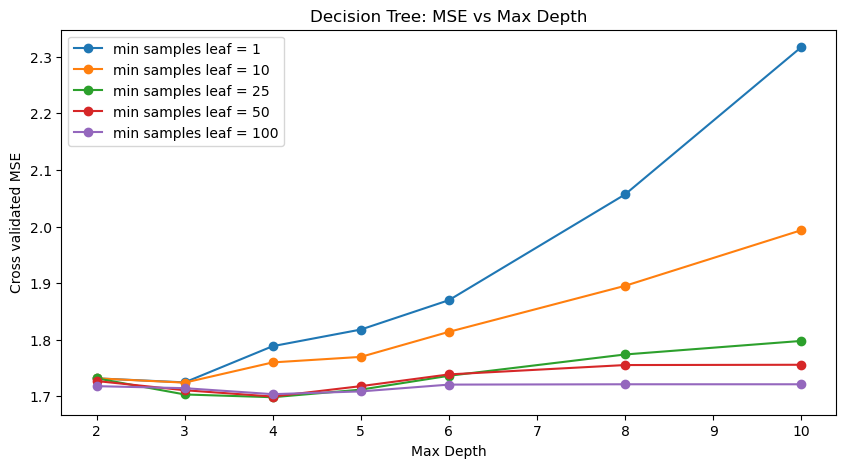

In [40]:
tree_cv_results = pd.DataFrame(tree_grid.cv_results_)

plt.figure(figsize=(10, 5))
for leaf in tree_params['tree__min_samples_leaf']:
    subset = tree_cv_results[tree_cv_results['param_tree__min_samples_leaf'] == leaf]
    plt.plot(subset['param_tree__max_depth'], -subset['mean_test_score'], marker='o', label=f'min samples leaf = {leaf}')
plt.xlabel('Max Depth')
plt.ylabel('Cross validated MSE')
plt.title('Decision Tree: MSE vs Max Depth')
plt.legend()
plt.show()

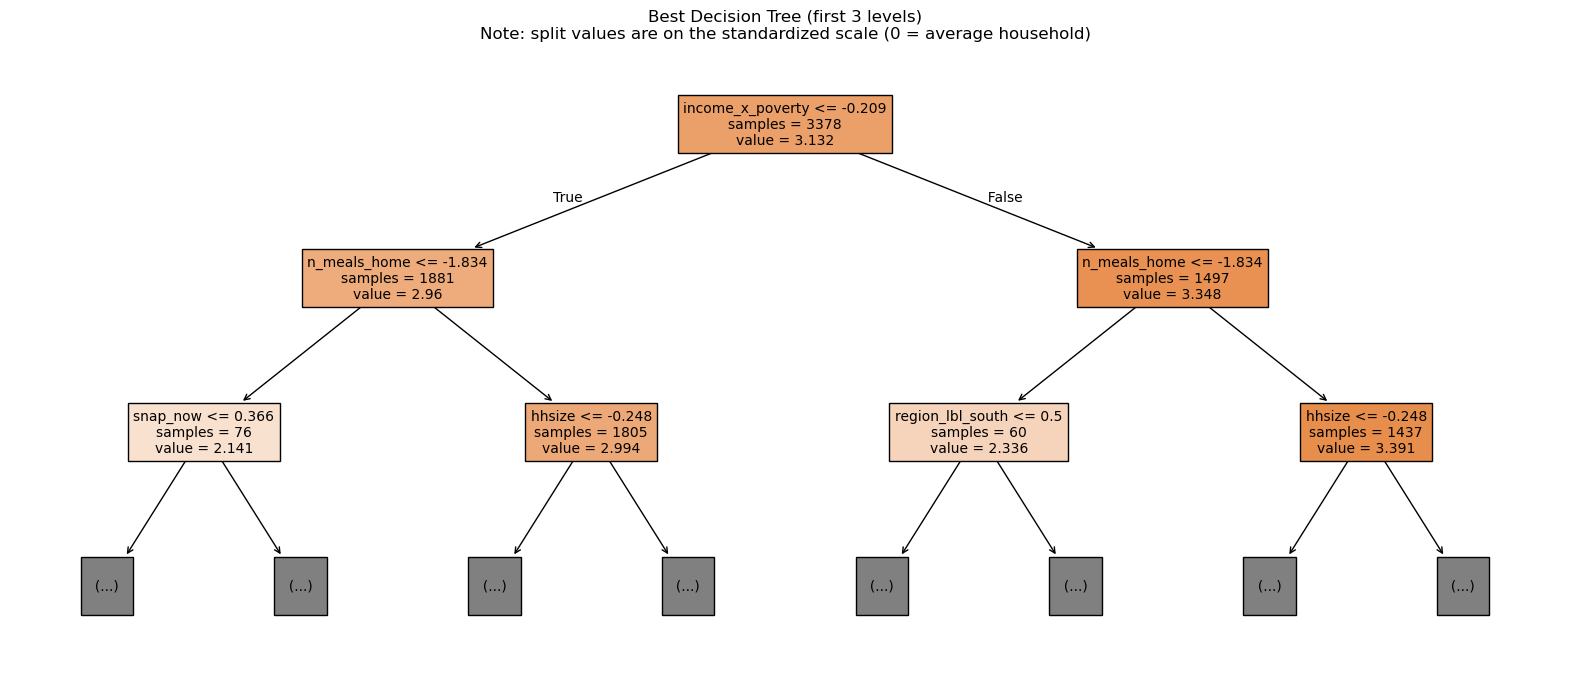

In [41]:
#plot the top levels of the best tree
tree_feature_names = get_feature_names(tree_best.named_steps['preprocessor'])

plt.figure(figsize=(20, 8))
plot_tree(tree_best.named_steps['tree'], feature_names=tree_feature_names, max_depth=2, filled=True, fontsize=10, impurity=False)
plt.title('Best Decision Tree (first 3 levels)\nNote: split values are on the standardized scale (0 = average household)')
plt.show()

### 9.6 Random Forest

In [42]:
#build random forest pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestRegressor(random_state=42, n_jobs=-1))])

rf_params = {'rf__n_estimators': [100, 300],
             'rf__max_depth': [4, 6, 8, 12],
             'rf__min_samples_leaf': [5, 20, 50],
             'rf__max_features': [0.5]}
rf_grid = GridSearchCV(rf_pipeline, rf_params, scoring='neg_mean_squared_error', cv=4)

#fit model and make predictions
rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
rf_training_predictions = rf_best.predict(X_train)
rf_test_predictions = rf_best.predict(X_test)

#get error metrics
rf_training_mse = mean_squared_error(y_train, rf_training_predictions)
rf_test_mse = mean_squared_error(y_test, rf_test_predictions)
rf_trainingr2 = r2_score(y_train, rf_training_predictions)
rf_testr2 = r2_score(y_test, rf_test_predictions)

print('Best parameters:', rf_grid.best_params_)
print(f'Training MSE:', rf_training_mse)
print(f'Test MSE:', rf_test_mse)
print(f'Training R2:', rf_trainingr2)
print(f'Test R2:', rf_testr2)

Best parameters: {'rf__max_depth': 8, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 300}
Training MSE: 1.311678186174394
Test MSE: 1.8218451901770247
Training R2: 0.264315681674655
Test R2: 0.07443771253133102


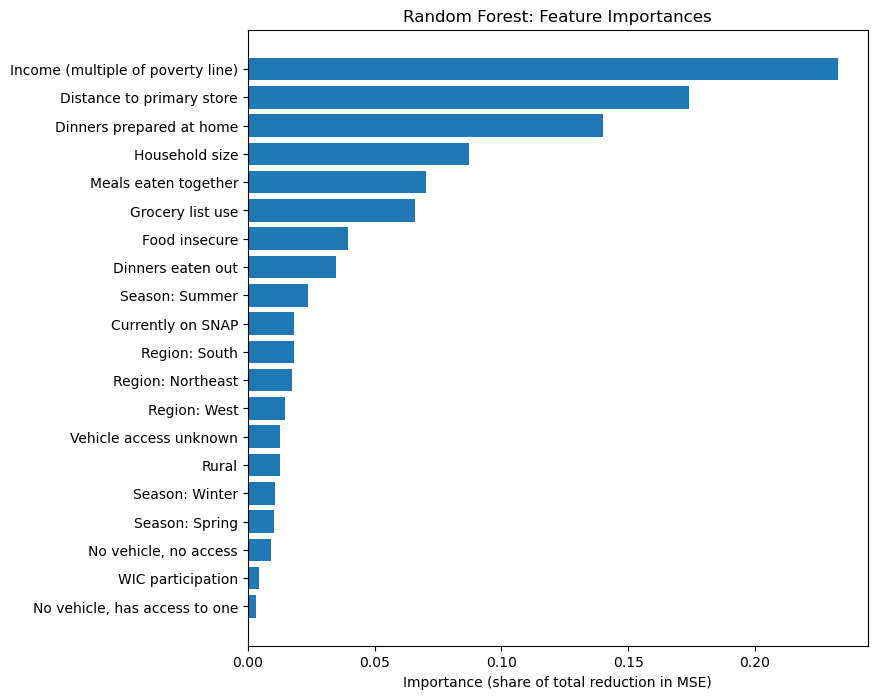

In [43]:
#Build a feature importance graph
rf_feature_names = get_feature_names(rf_best.named_steps['preprocessor'])
rf_importances = pd.Series(rf_best.named_steps['rf'].feature_importances_, index=rf_feature_names).sort_values()

plt.figure(figsize=(8, 8))
plt.barh(readable(rf_importances.index), rf_importances.values)
plt.title('Random Forest: Feature Importances')
plt.xlabel('Importance (share of total reduction in MSE)')
plt.show()

### 9.7 Gradient Boosting

In [44]:
#build gradient boosting pipeline
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('gb', GradientBoostingRegressor(subsample=0.8, random_state=42))])

gb_params = {'gb__learning_rate': [0.01, 0.05, 0.1],
             'gb__max_depth': [2, 3],
             'gb__n_estimators': [100, 300, 500]}
gb_grid = GridSearchCV(gb_pipeline, gb_params, scoring='neg_mean_squared_error', cv=4, n_jobs=-1)

#fit model and make predictions
gb_grid.fit(X_train, y_train)
gb_best = gb_grid.best_estimator_
gb_training_predictions = gb_best.predict(X_train)
gb_test_predictions = gb_best.predict(X_test)

#get error metrics
gb_training_mse = mean_squared_error(y_train, gb_training_predictions)
gb_test_mse = mean_squared_error(y_test, gb_test_predictions)
gb_trainingr2 = r2_score(y_train, gb_training_predictions)
gb_testr2 = r2_score(y_test, gb_test_predictions)

print('Best parameters:', gb_grid.best_params_)
print(f'Training MSE:', gb_training_mse)
print(f'Test MSE:', gb_test_mse)
print(f'Training R2:', gb_trainingr2)
print(f'Test R2:', gb_testr2)

Best parameters: {'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 500}
Training MSE: 1.485403113407913
Test MSE: 1.8161264554355483
Training R2: 0.16687813486245318
Test R2: 0.07734303359663686


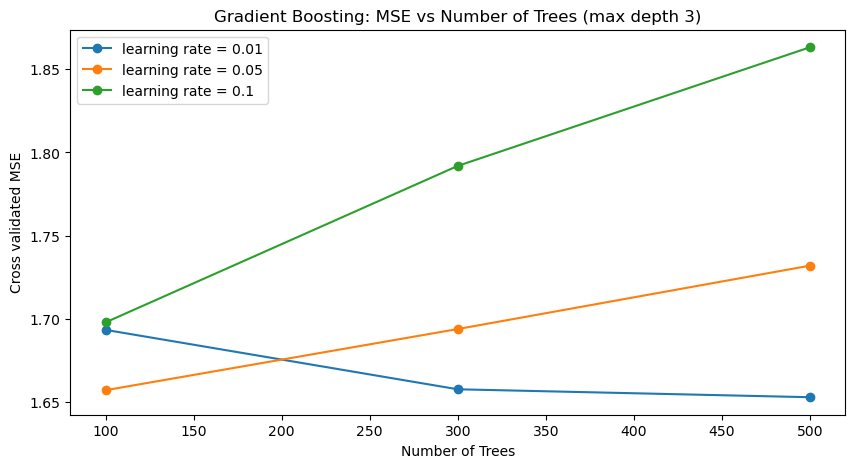

In [45]:
gb_cv_results = pd.DataFrame(gb_grid.cv_results_)
gb_depth = gb_grid.best_params_['gb__max_depth']
gb_subset = gb_cv_results[gb_cv_results['param_gb__max_depth'] == gb_depth]

plt.figure(figsize=(10, 5))
for rate in gb_params['gb__learning_rate']:
    line = gb_subset[gb_subset['param_gb__learning_rate'] == rate]
    plt.plot(line['param_gb__n_estimators'], -line['mean_test_score'], marker='o', label=f'learning rate = {rate}')
plt.xlabel('Number of Trees')
plt.ylabel('Cross validated MSE')
plt.title(f'Gradient Boosting: MSE vs Number of Trees (max depth {gb_depth})')
plt.legend()
plt.show()

### 9.8 Neural Network

The grid searches over the number and size of hidden layers and alpha. Early stopping is used

In [46]:
#build the neural network pipeline
mlp_pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('mlp', MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=25, random_state=42))])

mlp_params = {'mlp__hidden_layer_sizes': [(8,), (16,), (32,), (16, 8), (32, 16)],
              'mlp__alpha': [0.1, 1.0, 10.0, 30.0, 100.0]}
mlp_grid = GridSearchCV(mlp_pipeline, mlp_params, scoring='neg_mean_squared_error', cv=4, n_jobs=-1)

#fit model and make predictions
mlp_grid.fit(X_train, y_train)
mlp_best = mlp_grid.best_estimator_
mlp_training_predictions = mlp_best.predict(X_train)
mlp_test_predictions = mlp_best.predict(X_test)

#get error metrics
mlp_training_mse = mean_squared_error(y_train, mlp_training_predictions)
mlp_test_mse = mean_squared_error(y_test, mlp_test_predictions)
mlp_trainingr2 = r2_score(y_train, mlp_training_predictions)
mlp_testr2 = r2_score(y_test, mlp_test_predictions)

print('Best parameters:', mlp_grid.best_params_)
print(f'Training MSE:', mlp_training_mse)
print(f'Test MSE:', mlp_test_mse)
print(f'Training R2:', mlp_trainingr2)
print(f'Test R2:', mlp_testr2)

Best parameters: {'mlp__alpha': 10.0, 'mlp__hidden_layer_sizes': (8,)}
Training MSE: 1.7024606301368355
Test MSE: 1.892607180706501
Training R2: 0.04513652711501859
Test R2: 0.038488099373511386


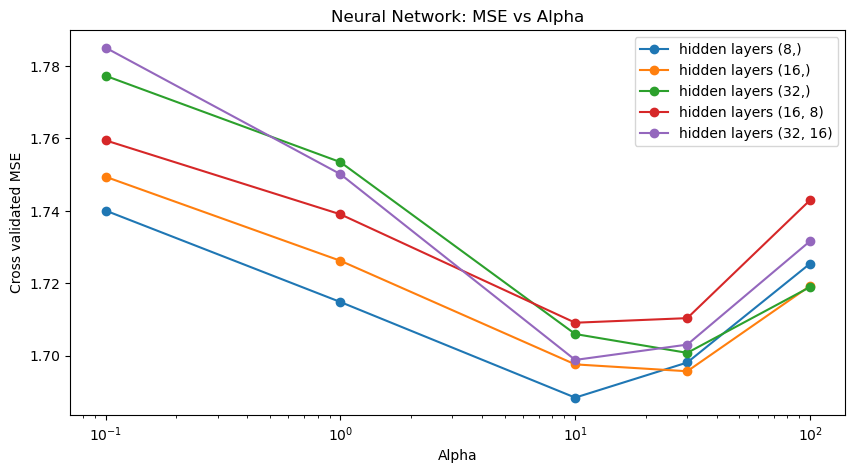

In [47]:
mlp_cv_results = pd.DataFrame(mlp_grid.cv_results_)
mlp_cv_results['hidden_layers'] = mlp_cv_results['param_mlp__hidden_layer_sizes'].astype(str)

plt.figure(figsize=(10, 5))
for layers in mlp_cv_results['hidden_layers'].unique():
    subset = mlp_cv_results[mlp_cv_results['hidden_layers'] == layers]
    plt.plot(subset['param_mlp__alpha'].astype(float), -subset['mean_test_score'], marker='o', label=f'hidden layers {layers}')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Cross validated MSE')
plt.title('Neural Network: MSE vs Alpha')
plt.legend()
plt.show()

## 10. Model Comparison

In [48]:
results_summary = pd.DataFrame([
    {'Model': 'Naive mean (reference)', 'Train R2': naive_results['Train R2'], 'Test R2': naive_results['Test R2'], 'Train MSE': naive_results['Train MSE'], 'Test MSE': naive_results['Test MSE'], 'CV MSE': np.nan},
    {'Model': 'Linear Regression', 'Train R2': linear_trainingr2, 'Test R2': linear_testr2, 'Train MSE': linear_training_mse, 'Test MSE': linear_test_mse, 'CV MSE': -linear_grid.best_score_},
    {'Model': f'Polynomial (degree {best_polynomial_degree})', 'Train R2': polynomial_trainingr2, 'Test R2': polynomial_testr2, 'Train MSE': polynomial_training_mse, 'Test MSE': polynomial_test_mse, 'CV MSE': -polynomial_grid.best_score_},
    {'Model': f'Ridge (alpha={ridge_grid.best_params_["ridge__alpha"]})', 'Train R2': ridge_trainingr2, 'Test R2': ridge_testr2, 'Train MSE': ridge_training_mse, 'Test MSE': ridge_test_mse, 'CV MSE': -ridge_grid.best_score_},
    {'Model': f'Lasso (alpha={lasso_grid.best_params_["lasso__alpha"]})', 'Train R2': lasso_trainingr2, 'Test R2': lasso_testr2, 'Train MSE': lasso_training_mse, 'Test MSE': lasso_test_mse, 'CV MSE': -lasso_grid.best_score_},
    {'Model': f'Decision Tree (depth {tree_grid.best_params_["tree__max_depth"]})', 'Train R2': tree_trainingr2, 'Test R2': tree_testr2, 'Train MSE': tree_training_mse, 'Test MSE': tree_test_mse, 'CV MSE': -tree_grid.best_score_},
    {'Model': 'Random Forest', 'Train R2': rf_trainingr2, 'Test R2': rf_testr2, 'Train MSE': rf_training_mse, 'Test MSE': rf_test_mse, 'CV MSE': -rf_grid.best_score_},
    {'Model': 'Gradient Boosting', 'Train R2': gb_trainingr2, 'Test R2': gb_testr2, 'Train MSE': gb_training_mse, 'Test MSE': gb_test_mse, 'CV MSE': -gb_grid.best_score_},
    {'Model': f'Neural Network {mlp_grid.best_params_["mlp__hidden_layer_sizes"]}', 'Train R2': mlp_trainingr2, 'Test R2': mlp_testr2, 'Train MSE': mlp_training_mse, 'Test MSE': mlp_test_mse, 'CV MSE': -mlp_grid.best_score_},
]).sort_values('Test MSE').reset_index(drop=True)

results_summary.round(4)

,Model,Train R2,Test R2,Train MSE,Test MSE,CV MSE
0,Gradient Boosting,0.1669,0.0773,1.4854,1.8161,1.6530
1,Random Forest,0.2643,0.0744,1.3117,1.8218,1.6533
2,Lasso (alpha=0.005),0.0578,0.0600,1.6799,1.8503,1.6968
3,Ridge (alpha=100.0),0.0585,0.0591,1.6786,1.8521,1.6957
4,Linear Regression,0.0593,0.0554,1.6773,1.8593,1.6987
5,Polynomial (degree 1),0.0593,0.0554,1.6773,1.8593,1.6987
6,Decision Tree (depth 4),0.0782,0.0491,1.6435,1.8717,1.6984
7,"Neural Network (8,)",0.0451,0.0385,1.7025,1.8926,1.6884
8,Naive mean (reference),0.0000,-0.0005,1.7829,1.9694,NaN


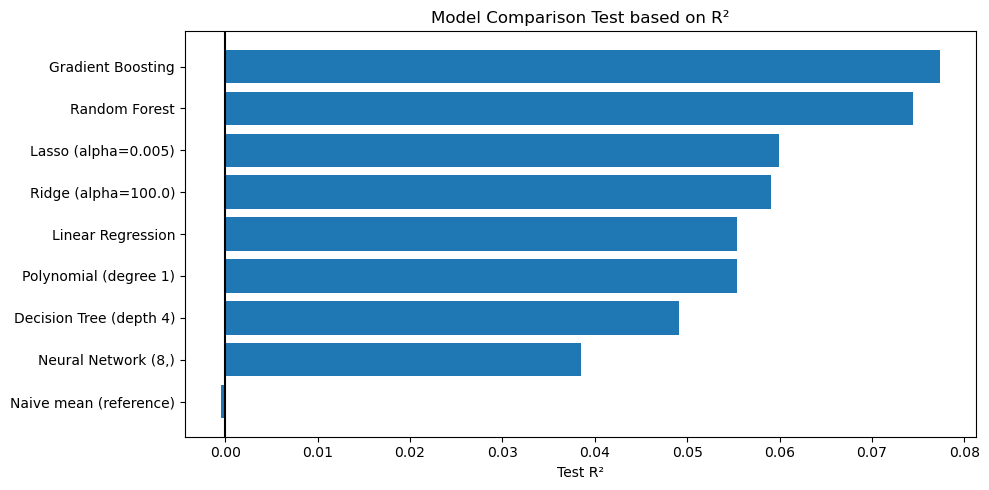

In [49]:
plt.figure(figsize=(10, 5))
plt.barh(results_summary['Model'], results_summary['Test R2'])
plt.gca().invert_yaxis()
plt.axvline(0, color='black')
plt.xlabel('Test R²')
plt.title('Model Comparison Test based on R²')
plt.tight_layout()
plt.show()

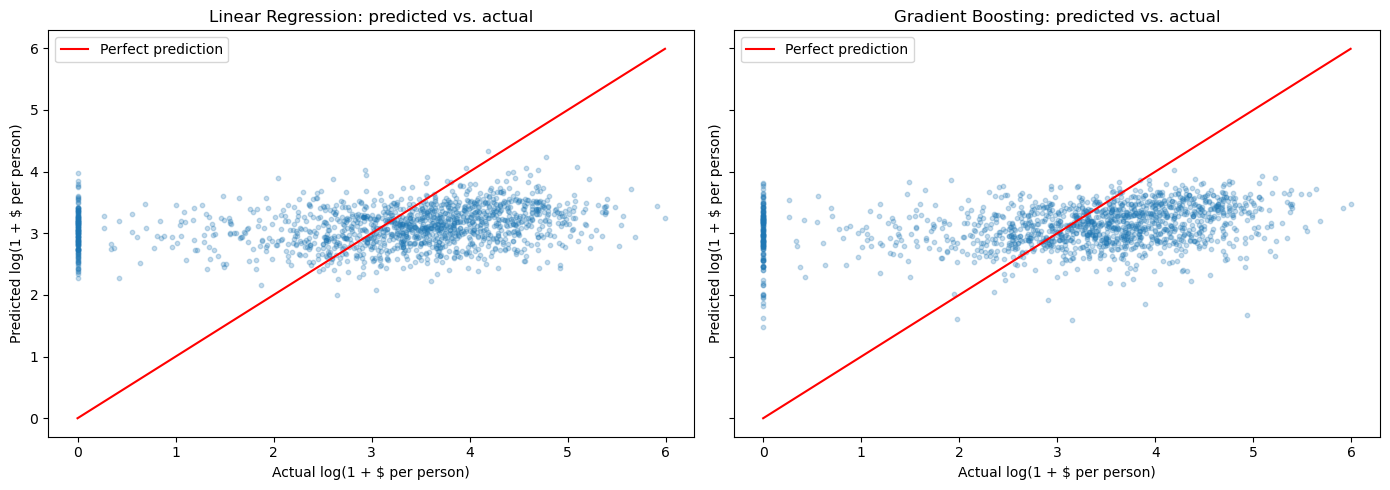

In [50]:
#predicted vs actual for the baseline and the best model on the test set
best_model_name = results_summary.loc[0, 'Model']
all_test_predictions = {
    'Linear Regression': linear_test_predictions,
    f'Polynomial (degree {best_polynomial_degree})': polynomial_test_predictions,
    f'Ridge (alpha={ridge_grid.best_params_["ridge__alpha"]})': ridge_test_predictions,
    f'Lasso (alpha={lasso_grid.best_params_["lasso__alpha"]})': lasso_test_predictions,
    f'Decision Tree (depth {tree_grid.best_params_["tree__max_depth"]})': tree_test_predictions,
    'Random Forest': rf_test_predictions,
    'Gradient Boosting': gb_test_predictions,
    f'Neural Network {mlp_grid.best_params_["mlp__hidden_layer_sizes"]}': mlp_test_predictions}
best_test_predictions = all_test_predictions[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
lims = [y_test.min(), y_test.max()]
for ax, predictions, title in zip(axes, [linear_test_predictions, best_test_predictions], ['Linear Regression', best_model_name]):
    ax.scatter(y_test, predictions, alpha=0.25, s=10)
    ax.plot(lims, lims, color='red', label='Perfect prediction')
    ax.set_title(f'{title}: predicted vs. actual')
    ax.set_xlabel('Actual log(1 + $ per person)')
    ax.set_ylabel('Predicted log(1 + $ per person)')
    ax.legend()
plt.tight_layout()
plt.show()

**Results:**

- The gradient boosting model had the lowest test MSE and the highest test R², so it is the preferable model
- The random forest is essentially tied with it, and their cross validated MSEs are nearly identical (1.6530 vs. 1.6533)
- The best model explains less than 8% of the variation in log FAH spending per person, and it lowers the test MSE by only about 8% compared to always predicting the mean and about 2% compared to linear regression

- Linear Models:
Linear ridge and lasso regression perform almost the same. The linear model is not overfitting. Lasso dropped WIC, the South region and two of the vehicle access categories, so these add little to our model

- Polynomial Models:
The grid search chose degree 1, which is the same model as linear regression. Squared terms and interactions (such as income × grocery list use) raised the training fit but made the cross validated MSE worse

- Decision Trees:
The best single tree is no better than linear regression on the test set. Its first splits are on income, then meals prepared at home, then household size. These are the same features the linear model found most important.

- Random Forest & Gradient Boosting:
Averaging many trees gives the best results. Both fit the training data much better than the test data. In the random forest, income, distance to the primary store, meals prepared at home and household size are the most important features.

- Neural Network:
The grid search chose a small network with one hidden layer of 8 neurons and a large penalty (alpha = 10). So it seems like the more complex networks overfit. It had a slightly better cross validated MSE than linear regression and the lowest test R² of the fitted models

## 11. Findings

**Research question:** Are income, grocery list use and other food planning behaviors associated with lower food-at-home (FAH) acquisition among US households?

**Answer:** they are associated with acquisition, but in the opposite direction from the hypothesis, and only modestly. The results of all the models highlight this relationship

1. Higher income, more grocery list use, and more meals prepared at home all go with more FAH acquisition per person, not less. All the regression coefficients have the same signs. Income and meals at home are also the first splits in the decision tree and among the most important features in the random forest

2. Eating out more is associated with lower FAH acquisition

3. Household size, food insecurity, season and region matter at least as much as the income and planning variables. Larger households spend less per person, food insecure households spend less, households surveyed in winter spent less (only about 200 households were surveyed in winter, all in December or January, so this estimate rests on a small group), and Western households spent more

4. More complex models improve the fit only a little. The relationships are mostly simple, and the main limitation is the data rather than the choice of model

5. Interpretation for the food waste motivation is that because FoodAPS measures acquisition rather than waste, higher spending among planners and home cooks does not by itself mean more waste. These households may simply eat more of their meals from food bought for home. About 10% of households bought nothing that week, which limits how much any household characteristic can explain. Possibly better data would yield different results

## 12. Next Steps

1. Collect new data on higher-income households. FoodAPS deliberately oversampled SNAP participants and other low-income households, and the median household in this sample is at about 175% of the poverty line. The strongest finding is that higher income goes with more food acquisition, so the group the conclusions matter most for is the one the sample covers least. New data should cover the full income range, especially the top. It should also follow households for several weeks instead of one, which would reduce the noise from households that happened to buy nothing that week. Ideally it would measure food waste directly, such as with waste diaries, so the waste question can be answered directly instead of using acquisition as a stand-in. FoodAPS was also collected in 2012–2013, so updated data would be helpful.

2. Fit a hurdle model.The residual plots show a separate cluster of households with zero spending that a single regression cannot reach. A hurdle model splits the problem in two: a classification model for whether a household acquires any food at home during the week, then a regression for how much it acquires among households that acquired some food.

3. Try other neural networks. Deeper networks built in Keras or PyTorch, with tuned learning rates, dropout and embeddings for the categorical variables, could test whether the small network here left anything out. Since all the models performed similarly, the main purpose is to confirm the result rather than to expect large gains.